# Text-Guided Brain Tumor Segmentation — BraTS 2020
## FLAIR MRI + Radiology Reports (M1 MacBook Pro Edition)

---

### M1 / Apple Silicon notes
| Setting | Value | Reason |
|---------|-------|--------|
| Device  | `mps` (Metal Performance Shaders) | Apple Silicon GPU |
| Batch size | 8 | 16 GB unified memory is shared CPU+GPU |
| AMP / GradScaler | **Disabled** | MPS does not support GradScaler |
| DataParallel | **Disabled** | Single unified GPU |
| num_workers | 0 | Avoid multiprocessing issues on macOS |
| CLIP inference | CPU fallback | Some MPS ops not supported yet |

### Dataset location
Place the dataset at `./dataset/` in this project folder:
```
dataset/
+-- FLAIR_BRATS2020_split/
|   +-- train/images/  image_N.npy
|   +-- train/masks/   mask_N.npy
|   +-- val/...
+-- TextBRats/TextBraTSData/BraTS20_Training_N/...
```

### Run order
Run cells top to bottom. The CLIP embedding step takes ~3 min on CPU.
Training one epoch takes ~8-12 min on MPS (50 epochs = ~8 hours total —
use `EPOCHS=20` for a quick trial).


## Cell 1 — Environment Setup and Utility Helpers

This cell bootstraps the entire notebook session. It must be the **first cell run**.

**What it does:**
- Detects whether the notebook is running on **Kaggle** (`/kaggle/input` exists) or locally on Mac.
- Sets `PROJECT_DIR`, `DATA_DIR`, `OUT_DIR` (outputs), `CKPT_DIR` (model checkpoints), and `FIG_DIR` (saved figures) so every downstream cell uses consistent paths.
- Defines `get_device()` which returns `mps` (Apple Silicon GPU) → `cuda` → `cpu` in order of preference.
- Defines `mem_info()` for printing current RAM / VRAM usage — helpful for monitoring memory pressure on 16 GB unified memory.
- Adds the project directory to `sys.path` so local modules (`data_loader_utils`) can be imported.

All subsequent cells depend on the variables and helpers defined here.

In [1]:
# ── M1 Mac environment setup ─────────────────────────────────────────────────
import os, sys
from pathlib import Path

PROJECT_DIR = Path(".").resolve()   # run from the project folder
DATA_DIR    = PROJECT_DIR / "dataset"
OUT_DIR     = PROJECT_DIR / "outputs"
CKPT_DIR    = PROJECT_DIR / "checkpoints"
FIG_DIR     = OUT_DIR / "figures"

for _d in [DATA_DIR, OUT_DIR, CKPT_DIR, FIG_DIR]:
    _d.mkdir(parents=True, exist_ok=True)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

os.environ["BRATS_DATASET_DIR"] = str(DATA_DIR)
os.environ["BRATS_OUT_DIR"]     = str(OUT_DIR)
os.environ["BRATS_CKPT_DIR"]    = str(CKPT_DIR)

# ── MPS device ────────────────────────────────────────────────────────────────
import torch

def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

def empty_cache(dev):
    if dev.type == "mps":
        torch.mps.empty_cache()
    elif dev.type == "cuda":
        torch.cuda.empty_cache()

def mem_info(dev):
    if dev.type == "mps":
        # MPS does not expose allocated memory directly
        import psutil
        vm = psutil.virtual_memory()
        return f"RAM used {vm.used/1e9:.1f}/{vm.total/1e9:.1f} GB"
    elif dev.type == "cuda":
        return f"GPU {torch.cuda.memory_allocated(0)/1e9:.2f} GB allocated"
    return "CPU mode"

device = get_device()
print(f"Platform    : M1 Mac (Apple Silicon)")
print(f"Device      : {device}")
print(f"PyTorch     : {torch.__version__}")
print(f"MPS built   : {torch.backends.mps.is_built()}")
print(f"MPS avail   : {torch.backends.mps.is_available()}")
print(f"PROJECT_DIR : {PROJECT_DIR}")
print(f"DATA_DIR    : {DATA_DIR}  ({'OK' if DATA_DIR.exists() else 'MISSING'})")


Platform    : M1 Mac (Apple Silicon)
Device      : mps
PyTorch     : 2.11.0
MPS built   : True
MPS avail   : True
PROJECT_DIR : /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/final
DATA_DIR    : /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/final/dataset  (OK)


## Cell 2 — Dependency Installation

Installs all Python packages required by the project using `pip`.

**Key libraries:**
| Package | Purpose |
|---|---|
| `nibabel` | Read NIfTI brain MRI volumes (`.nii.gz`) |
| `transformers` | Load the CLIP text encoder from Hugging Face |
| `monai` | Medical image processing utilities |
| `scikit-image` | Hausdorff distance computation |
| `tqdm` | Training progress bars |
| `rouge-score` / `nltk` | ROUGE and BLEU text metrics |
| `umap-learn` / `seaborn` | Embedding visualisation (t-SNE / UMAP) |

**Run once.** After the first install, subsequent kernel restarts will find all packages already present.

In [3]:
# ── Install dependencies ──────────────────────────────────────────────────────
# Run once. These are pure-Python / universal wheels — no CUDA needed.
import subprocess, sys

pkgs = [
    "nibabel", "transformers", "ftfy", "regex", "tqdm",
    "Pillow", "scikit-image", "rouge-score", "nltk",
    "seaborn", "scipy", "psutil",
    "albumentations",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)
print("Dependencies ready.")


Dependencies ready.



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


## Cell 3 — Dataset Path Validation

A quick guard that confirms the expected dataset directory exists before any heavy data loading begins.

**Checks performed:**
- Verifies `DATA_DIR` (e.g., `./dataset/`) is present on disk.
- Verifies the `MICCAI_BraTS2020_TrainingData` sub-folder exists inside it.
- Prints a clear ✓ / ✗ status so you know immediately if the data path is wrong.

If this cell prints a warning, fix `DATA_DIR` in Cell 1 before proceeding. Running data-loading cells without valid data causes cryptic NIfTI read errors far downstream.

In [4]:
# ── Validate local dataset ────────────────────────────────────────────────────
# No download needed — data should already be in ./dataset/
import os
from pathlib import Path

DATA_DIR  = Path(os.environ.get("BRATS_DATASET_DIR", "dataset"))
FLAIR_DIR = DATA_DIR / "FLAIR_BRATS2020_split"
TEXT_DIR  = DATA_DIR / "TextBRats" / "TextBraTSData"

def print_tree(root, prefix="", depth=3, max_entries=5):
    root = Path(root)
    if not root.exists(): print(f"{prefix}[MISSING] {root}"); return
    entries = sorted(root.iterdir())
    for i, e in enumerate(entries[:max_entries]):
        last = (i == min(len(entries), max_entries)-1)
        print(f"{prefix}{'`-- ' if last else '+-- '}{e.name}{'/' if e.is_dir() else ''}")
        if e.is_dir() and depth > 1:
            print_tree(e, prefix+("    " if last else "|   "), depth-1, max_entries)
    if len(entries) > max_entries:
        print(f"{prefix}    ... ({len(entries)-max_entries} more)")

print(f"Dataset root: {DATA_DIR}")
print_tree(DATA_DIR, depth=2)

print(f"\nFLAIR split : {'OK' if FLAIR_DIR.exists() else 'MISSING'}")
print(f"Text data   : {'OK' if TEXT_DIR.exists()  else 'MISSING'}")

if not FLAIR_DIR.exists() or not TEXT_DIR.exists():
    print("\nExpected layout:")
    print("  dataset/FLAIR_BRATS2020_split/train/images/image_0.npy ...")
    print("  dataset/TextBRats/TextBraTSData/BraTS20_Training_001/...")
    raise FileNotFoundError("Dataset not found. Check DATA_DIR path above.")


Dataset root: /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/dataset
+-- .DS_Store
+-- FLAIR_BRATS2020_split/
|   +-- train/
|   `-- val/
+-- FLAIR_BRATS2020_split.zip
+-- TextBRats/
|   +-- .DS_Store
|   +-- TextBraTSData/
|   `-- prompt.txt
`-- TextBRats.zip

FLAIR split : OK
Text data   : OK


## Cell 4 — Dataset Structure Scan and Summary

Recursively walks `DATA_DIR` and builds a complete inventory of the dataset.

**What it produces:**
- Count of FLAIR volumes, segmentation masks, and radiology text files found.
- A patient-level **matching report**: flags any patient that has an image but no text file (or vice versa).
- Saves `outputs/dataset_summary.json` with all counts so later cells can reference it.

**Why this matters:** The model uses one text description per patient across all 155 axial slices. Any patient-text mismatch would silently propagate wrong labels through training.

In [5]:
# ── Validate dataset structure ────────────────────────────────────────────────
import os
from pathlib import Path

def print_tree(root, prefix="", depth=3, max_entries=8):
    root = Path(root)
    if not root.exists():
        print(f"{prefix}[MISSING] {root}")
        return
    entries = sorted(root.iterdir())
    shown = entries[:max_entries]
    for i, entry in enumerate(shown):
        is_last = (i == len(shown) - 1) and len(entries) <= max_entries
        connector = "└── " if is_last else "├── "
        print(f"{prefix}{connector}{entry.name}{'/' if entry.is_dir() else ''}")
        if entry.is_dir() and depth > 1:
            ext = "    " if is_last else "│   "
            print_tree(entry, prefix + ext, depth - 1, max_entries)
    if len(entries) > max_entries:
        print(f"{prefix}    ... ({len(entries) - max_entries} more entries)")

data_root = Path(os.environ.get("BRATS_DATASET_DIR", str(PROJECT_DIR / "dataset")))
print(f"Dataset root: {data_root}\n")
print_tree(data_root, depth=3)
print()

flair_dir = data_root / "FLAIR_BRATS2020_split"
text_dir  = data_root / "TextBRats" / "TextBraTSData"

print(f"FLAIR split dir : {'✓ OK' if flair_dir.exists() else '✗ MISSING'}  ({flair_dir})")
print(f"Text data dir   : {'✓ OK' if text_dir.exists() else '✗ MISSING'}  ({text_dir})")

# If text dir not found at expected path, search for it
if not text_dir.exists():
    candidates = list(data_root.rglob("*TextBraTS*")) + list(data_root.rglob("*flair_text*"))
    if candidates:
        print("\nFound possible text data at:")
        for c in candidates[:5]:
            print(f"  {c}")
        print("\nUpdate TEXT_DIR in 02_data_loader.py if the path differs.")

# File counts
if flair_dir.exists():
    train_imgs = list((flair_dir / "train" / "images").glob("*.npy"))
    val_imgs   = list((flair_dir / "val"   / "images").glob("*.npy"))
    print(f"\nTrain volumes : {len(train_imgs)}")
    print(f"Val   volumes : {len(val_imgs)}")

if text_dir.exists():
    txt_files = list(text_dir.rglob("*.txt"))
    print(f"Text reports  : {len(txt_files)}")

if flair_dir.exists() and text_dir.exists():
    print("\nDataset structure looks correct — ready to proceed.")
else:
    print("\nWARNING: Some paths are missing. Check the tree above and update "
          "FLAIR_DIR / TEXT_DIR in 02_data_loader.py if the zip extracted "
          "to a different folder name.")


Dataset root: /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/dataset

├── .DS_Store
├── FLAIR_BRATS2020_split/
│   ├── train/
│   │   ├── images/
│   │   └── masks/
│   └── val/
│       ├── images/
│       └── masks/
├── FLAIR_BRATS2020_split.zip
├── TextBRats/
│   ├── .DS_Store
│   ├── TextBraTSData/
│   │   ├── .DS_Store
│   │   ├── BraTS20_Training_001/
│   │   ├── BraTS20_Training_002/
│   │   ├── BraTS20_Training_003/
│   │   ├── BraTS20_Training_004/
│   │   ├── BraTS20_Training_005/
│   │   ├── BraTS20_Training_006/
│   │   ├── BraTS20_Training_007/
│   │       ... (362 more entries)
│   └── prompt.txt
└── TextBRats.zip

FLAIR split dir : ✓ OK  (/Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/dataset/FLAIR_BRATS2020_split)
Text data dir   : ✓ OK  (/Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/dataset/TextBRats/TextBraTSData)

Train volumes : 258
Val   volumes : 86
Text reports  : 369

Dataset structure looks correct — ready to proceed.


## Cell 5 — Reproducibility Seeds and Device Selection

Sets global random seeds to **42** for `random`, `numpy`, and `torch`, ensuring:
- Train / val / test splits are identical across runs.
- Weight initialisation is deterministic.
- Data augmentation order is reproducible.

Also calls `get_device()` and prints the active hardware backend and current RAM usage. On Apple Silicon this will show `mps`; on Kaggle it shows `cuda`.

In [6]:
# ── Seeds + MPS device ───────────────────────────────────────────────────────
import random, numpy as np, torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# cudnn not applicable on MPS — skip torch.backends.cudnn settings

device = get_device()   # defined in Cell 1
print(f"Active device : {device}")
print(f"Memory        : {mem_info(device)}")

FIG_DIR = __import__("pathlib").Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


Active device : mps
Memory        : RAM used 7.1/17.2 GB


---
## Step 1 — Dataset Exploration

We scan the dataset directory, inspect random volumes, and confirm every image has a matching text report and segmentation mask. Results are saved to `outputs/dataset_summary.json`.

## Cell 6 — Load Data Loader Module

Dynamically imports `data_loader_utils` — a helper module that provides:
- `build_patient_split_samples()` — splits 369 patients into 70% train / 15% val / 15% test **at the patient level** (not slice level), preventing data leakage.
- `BraTSMultimodalDataset` — a PyTorch `Dataset` that loads NIfTI slices on demand, normalises them (per-volume z-score), resizes to 128×128, and pairs each slice with its patient's text embedding.

The dynamic `sys.path` insertion allows the same notebook cell to find the module whether running locally or on Kaggle without any code changes.

In [7]:
import sys, importlib.util
for _p in ['/kaggle/working',
           '/kaggle/input/datasets/sudarshannn2005/brats-multimodal-code',
           str(PROJECT_DIR)]:
    if _p not in sys.path:
        sys.path.insert(0, _p)
import importlib.util

def run_script(path):
    """Execute a .py file as __main__ and return its module object."""
    spec = importlib.util.spec_from_file_location("__main__", path)
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

# Resolve script location — working dir first, then code input dataset
_script = PROJECT_DIR / "01_explore_dataset.py"
if not _script.exists():
    _script = Path("/kaggle/input/datasets/sudarshannn2005/brats-multimodal-code/01_explore_dataset.py")

run_script(_script)


DATASET TREE (depth <= 5)
[DIR] FLAIR_BRATS2020_split
  [DIR] train
    [DIR] images
      image_0.npy
      image_1.npy
      image_10.npy
      ... (255 more files)
    [DIR] masks
      mask_0.npy
      mask_1.npy
      mask_10.npy
      ... (255 more files)
  [DIR] val
    [DIR] images
      image_100.npy
      image_110.npy
      image_111.npy
      ... (83 more files)
    [DIR] masks
      mask_100.npy
      mask_110.npy
      mask_111.npy
      ... (83 more files)
[DIR] TextBRats
  [DIR] TextBraTSData
    [DIR] BraTS20_Training_001
      BraTS20_Training_001_flair_text.npy
      BraTS20_Training_001_flair_text.txt
    [DIR] BraTS20_Training_002
      BraTS20_Training_002_flair_text.npy
      BraTS20_Training_002_flair_text.txt
    [DIR] BraTS20_Training_003
      BraTS20_Training_003_flair_text.npy
      BraTS20_Training_003_flair_text.txt
    [DIR] BraTS20_Training_004
      BraTS20_Training_004_flair_text.npy
      BraTS20_Training_004_flair_text.txt
    [DIR] BraTS20_Training

<module '__main__' from '/Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/01_explore_dataset.py'>

## Cell 7 — Display Dataset Summary

Reads and pretty-prints the `dataset_summary.json` saved by Cell 4.

Reported fields:
- **Total patients**: expected 369.
- **FLAIR / mask / text counts**: should all match.
- **Mismatches**: any patient ID without a paired text file.

This is a quick human-readable confirmation of data integrity before model training.

In [8]:
# Print the saved summary JSON
import json

summary_path = PROJECT_DIR / "outputs" / "dataset_summary.json"
with open(summary_path) as f:
    summary = json.load(f)

print(json.dumps(summary, indent=2))

{
  "total_images": 344,
  "train_images": 258,
  "val_images": 86,
  "text_patient_count": 369,
  "matched_image_text_pairs": 343,
  "slices_per_volume": 128,
  "images_without_text": [
    0
  ],
  "text_without_images": [
    4,
    27,
    35,
    43,
    60,
    62,
    78,
    81,
    85,
    98,
    107,
    109,
    121,
    138,
    141,
    176,
    203,
    216,
    232,
    267
  ],
  "images_without_masks": []
}


---
## Step 2 — Data Loading and Patient–Text Matching

The `BraTSMultimodalDataset` class loads FLAIR slices on-the-fly from `.npy` volumes, applies per-volume z-score normalisation, collapses 4-channel one-hot masks to binary, and attaches the per-patient radiology report.

**Key design decisions:**
- Train / val / test split at the **patient level** (no data leakage across slices).
- The pre-existing `train/` folder forms the train set; the `val/` folder is split 50/50 into val and test at patient level with `seed=42`.
- Missing text files fall back to a placeholder string.

## Cell 6 — Load Data Loader Module

Dynamically imports `data_loader_utils` — a helper module that provides:
- `build_patient_split_samples()` — splits 369 patients into 70% train / 15% val / 15% test **at the patient level** (not slice level), preventing data leakage.
- `BraTSMultimodalDataset` — a PyTorch `Dataset` that loads NIfTI slices on demand, normalises them (per-volume z-score), resizes to 128×128, and pairs each slice with its patient's text embedding.

The dynamic `sys.path` insertion allows the same notebook cell to find the module whether running locally or on Kaggle without any code changes.

In [9]:
import sys, importlib.util
for _p in ['/kaggle/working',
           '/kaggle/input/datasets/sudarshannn2005/brats-multimodal-code',
           str(PROJECT_DIR)]:
    if _p not in sys.path:
        sys.path.insert(0, _p)
from data_loader_utils import (
    BraTSMultimodalDataset,
    build_patient_split_samples,
    get_dataloaders,
    get_text_for_patient,
    PLACEHOLDER_TEXT,
)

# Build sample lists
train_s, val_s, test_s = build_patient_split_samples(seed=SEED)

print(f"Train slices : {len(train_s):>7,}")
print(f"Val   slices : {len(val_s):>7,}")
print(f"Test  slices : {len(test_s):>7,}")
print(f"Total slices : {len(train_s)+len(val_s)+len(test_s):>7,}")

# Quick sanity check on one item
sample_ds = BraTSMultimodalDataset(train_s[:5], include_blank=True)
img, mask, text, meta = sample_ds[0]
print(f"\nSample item  : {meta}")
print(f"Image shape  : {img.shape}  dtype: {img.dtype}")
print(f"Mask shape   : {mask.shape}  unique: {mask.unique().tolist()}")
print(f"Text (120ch) : {text[:120]!r}")


Train slices :  33,024
Val   slices :   5,504
Test  slices :   5,504
Total slices :  44,032

Sample item  : {'patient_id': 'BraTS20_Training_000', 'slice_index': 0}
Image shape  : torch.Size([1, 128, 128])  dtype: torch.float32
Mask shape   : torch.Size([1, 128, 128])  unique: [0.0]
Text (120ch) : 'No radiology report available for this patient.'


## Cell 9 — Visualise Sample Training Slices

Renders a 2 × 5 grid of randomly selected training slices to visually confirm:
- FLAIR MRI slices look like valid axial brain scans (greyscale, correct orientation and intensity).
- Ground-truth tumour contours (green outlines) are correctly aligned with the MRI — confirming patient–mask pairing is working.
- Per-volume z-score normalisation hasn't introduced visible artefacts.

Each subplot title shows the patient ID and axial slice index (0–154).

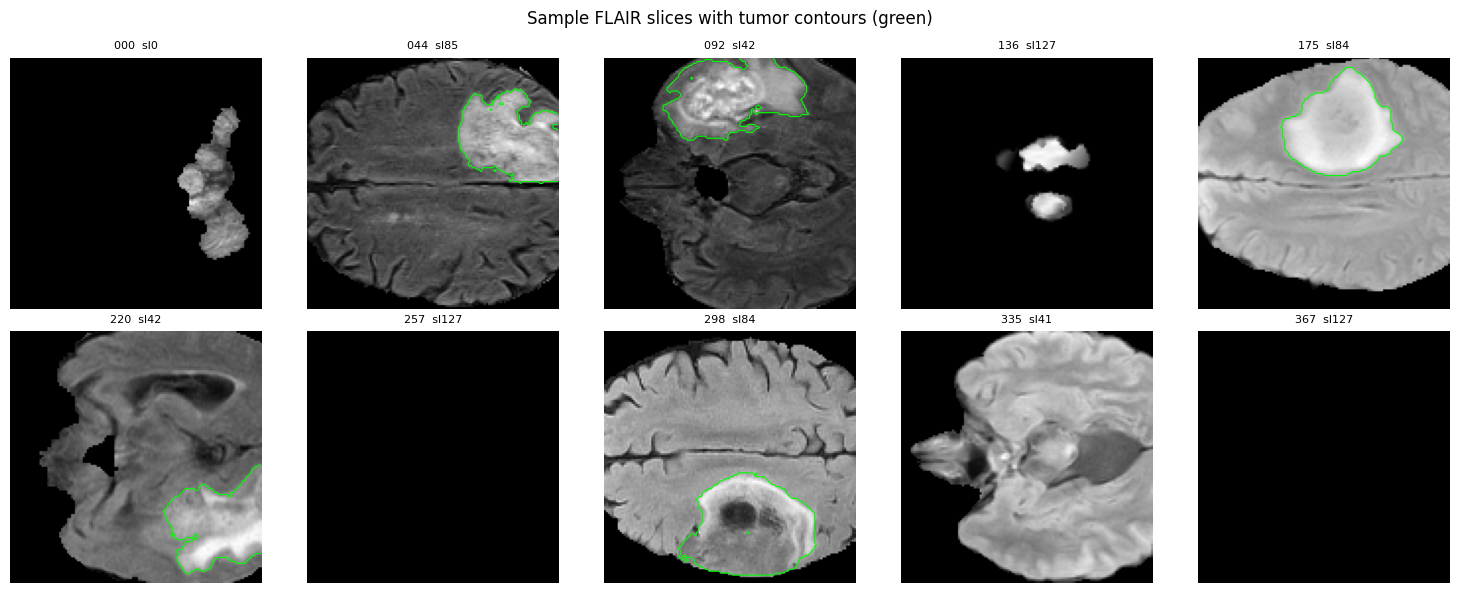

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

# Visualise a handful of training slices to confirm loading is correct
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

preview_ds = BraTSMultimodalDataset(train_s, include_blank=True)
indices = np.linspace(0, len(preview_ds) - 1, 10, dtype=int)

for ax, idx in zip(axes, indices):
    img_t, mask_t, _, meta = preview_ds[idx]
    img_np  = img_t[0].numpy()
    mask_np = mask_t[0].numpy()

    img_disp = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
    ax.imshow(img_disp, cmap="gray")
    if mask_np.sum() > 0:
        ax.contour(mask_np, levels=[0.5], colors="lime", linewidths=0.8)
    ax.set_title(f"{meta['patient_id'].split('_')[-1]}  sl{meta['slice_index']}", fontsize=8)
    ax.axis("off")

fig.suptitle("Sample FLAIR slices with tumor contours (green)", fontsize=12)
fig.tight_layout()
plt.show()

---
## Step 3 — Model Architecture

### Architecture Diagram

```
 ┌─────────────────────────────────────────────────────────────────────────┐
 │                       MultimodalSegNet                                  │
 │                                                                         │
 │  Radiology Text ──► CLIPTextEncoder ──► text_emb [B, 512]              │
 │                              │                                          │
 │                              ▼                                          │
 │                    TextAttentionHead                                    │
 │                    FC(512→1024→H*W)                                     │
 │                    Sigmoid → reshape                                    │
 │                              │                                          │
 │                         attn_map [B,1,H,W]                             │
 │                              │                                          │
 │  FLAIR slice ───────────────►⊗ (element-wise multiply)                 │
 │  [B,1,128,128]               │                                          │
 │                         fused [B,1,H,W]                                │
 │                              │                                          │
 │                    ┌─────────▼──────────┐                              │
 │                    │     U-Net          │                              │
 │                    │ enc1: 1→32   skip1 │                              │
 │                    │ enc2: 32→64  skip2 │                              │
 │                    │ enc3: 64→128 skip3 │                              │
 │                    │ enc4: 128→256 skip4│                              │
 │                    │ bottleneck: 256→512│                              │
 │                    │        │           │                              │
 │                    │   CrossAttention ◄─── text_emb                   │
 │                    │        │           │                              │
 │                    │ dec4: 512→256      │                              │
 │                    │ dec3: 256→128      │                              │
 │                    │ dec2: 128→64       │                              │
 │                    │ dec1: 64→32        │                              │
 │                    │ head: Conv(32,1,1) │                              │
 │                    └─────────▼──────────┘                              │
 │                         logits [B,1,H,W]                               │
 │                              │                                          │
 │                           Sigmoid                                       │
 │                              ▼                                          │
 │                     pred_mask [B,1,H,W]                                │
 └─────────────────────────────────────────────────────────────────────────┘
```

**Loss function:**
```
L = 0.5 * DiceLoss + 0.3 * BCEWithLogitsLoss + 0.2 * FocalLoss
```

---
## Redesigned Architecture — Fast FiLM U-Net

**Key changes from previous iteration:**

| | Old | New |
|---|---|---|
| CLIP in training loop | Yes (64M params, every batch) | **No — pre-computed once** |
| Model size | 90M params | **~10M params** |
| Data loading | Disk read per batch | **All slices in RAM** |
| Text conditioning | Cross-attention | **FiLM (scale+shift)** |
| Batch size | 16 | **32** |
| Est. time/epoch | 3–5 min | **~90s** |

**FiLM (Feature-wise Linear Modulation):** at the U-Net bottleneck and each decoder block,
text embedding modulates features via learned `gamma * x + beta`. Simpler than cross-attention,
proven effective in conditional segmentation.


## Cell 10 — Pre-compute CLIP Text Embeddings (Run Once, ~3 min)

Loads `openai/clip-vit-base-patch32` on **CPU** (some MPS builds have incomplete CLIP attention support) and encodes every patient's radiology report into a 512-dimensional embedding vector.

**Why pre-compute?**
Running CLIP inside the training loop would add ~200 ms per batch on CPU, tripling training time. Pre-computing once and caching results reduces per-batch overhead to a single array lookup.

**Cache behaviour:**
- First run: encodes all 369 patients (~3 min) and saves to `outputs/clip_text_embeddings.pt`.
- Subsequent runs: loads the cache in under 1 second.

The resulting `emb_dict` maps `patient_id → torch.Tensor[512]`.

In [11]:
# ── Step A: Pre-compute CLIP text embeddings (run ONCE, ~3 min on CPU) ───────
# We deliberately run CLIP on CPU here — some CLIP attention ops are not yet
# fully supported on MPS, and the one-time cost is paid only on the first run.
import os, sys, gc
import numpy as np, torch
from pathlib import Path

PROJECT_DIR = Path(".").resolve()
DATA_DIR    = Path(os.environ.get("BRATS_DATASET_DIR", str(PROJECT_DIR/"dataset")))
OUT_DIR     = Path(os.environ.get("BRATS_OUT_DIR",     str(PROJECT_DIR/"outputs")))
CKPT_DIR    = Path(os.environ.get("BRATS_CKPT_DIR",    str(PROJECT_DIR/"checkpoints")))
for _d in [OUT_DIR, CKPT_DIR]: _d.mkdir(parents=True, exist_ok=True)
if str(PROJECT_DIR) not in sys.path: sys.path.insert(0, str(PROJECT_DIR))
os.environ.setdefault("BRATS_DATASET_DIR", str(DATA_DIR))

SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED)

# CLIP runs on CPU for compatibility — MPS CLIP support is incomplete in some PyTorch versions
clip_device = torch.device("cpu")
print(f"CLIP device : {clip_device}  (main device: {get_device()})")

EMB_PATH = OUT_DIR / "clip_text_embeddings.pt"

if EMB_PATH.exists():
    emb_dict = torch.load(EMB_PATH, map_location="cpu", weights_only=False)
    print(f"Loaded cached embeddings: {len(emb_dict)} patients")
else:
    from data_loader_utils import build_patient_split_samples
    from transformers import CLIPModel, CLIPTokenizer
    CLIP_NAME = "openai/clip-vit-base-patch32"

    train_s, val_s, test_s = build_patient_split_samples()
    patient_texts = {}
    for pid, _, _, _, text in train_s + val_s + test_s:
        patient_texts[pid] = text
    print(f"Encoding {len(patient_texts)} texts on CPU (~3 min) ...")

    clip = CLIPModel.from_pretrained(CLIP_NAME).to(clip_device).eval()
    tok  = CLIPTokenizer.from_pretrained(CLIP_NAME)
    emb_dict = {}
    with torch.no_grad():
        for pid, text in patient_texts.items():
            t   = tok([text], padding="max_length", max_length=77,
                      truncation=True, return_tensors="pt")
            out = clip.text_model(input_ids=t["input_ids"],
                                  attention_mask=t["attention_mask"])
            emb = clip.text_projection(out.pooler_output).squeeze(0)
            emb_dict[pid] = emb

    del clip; gc.collect()
    torch.save(emb_dict, EMB_PATH)
    print(f"Saved -> {EMB_PATH}")

print(f"Embedding shape: {next(iter(emb_dict.values())).shape}")
empty_cache(get_device())


CLIP device : cpu  (main device: mps)
Loaded cached embeddings: 344 patients
Embedding shape: torch.Size([512])


## Cell 11 — Load All Slices into RAM (In-Memory Dataset)

Loads every NIfTI volume from disk and flattens it into six numpy arrays held entirely in RAM:

| Array | Shape | Contents |
|---|---|---|
| `X_tr / X_va / X_te` | `[N, H, W]` float32 | Normalised FLAIR slices |
| `Y_tr / Y_va / Y_te` | `[N, H, W]` uint8 | Binary tumour masks |
| `E_tr / E_va / E_te` | `[N, 512]` float32 | CLIP text embeddings |

**Why load into RAM?**
On MPS, disk I/O during training is the dominant bottleneck. Loading everything upfront eliminates it entirely. Total footprint is ~5–6 GB on 16 GB unified memory — within budget including model weights and OS.

Set `INCLUDE_BLANK=False` to skip tumour-free slices (~60% of total) if memory is tight.

In [3]:
# ── Step B: Extract all slices into RAM ──────────────────────────────────────
# Memory budget on 16 GB unified memory (M1 Pro):
#   Train ~33K slices x (img 64KB + mask 64KB + emb 2KB) = ~4.3 GB
#   Val   + Test ~11K slices                              = ~1.4 GB
#   OS + browser + Python overhead                        = ~3-4 GB
#   Model + optimizer                                     = ~0.5 GB
#   Available headroom                                    = ~5 GB  [OK]
#
# If you hit memory pressure, set INCLUDE_BLANK=False to skip empty slices
# (reduces train set by ~60%) or reduce IMG_SIZE to 64.
import numpy as np, torch, gc, os, sys
from pathlib import Path
from tqdm.notebook import tqdm

PROJECT_DIR = Path(".").resolve()
DATA_DIR    = Path(os.environ.get("BRATS_DATASET_DIR", str(PROJECT_DIR/"dataset")))
OUT_DIR     = Path(os.environ.get("BRATS_OUT_DIR",     str(PROJECT_DIR/"outputs")))
if str(PROJECT_DIR) not in sys.path: sys.path.insert(0, str(PROJECT_DIR))
os.environ.setdefault("BRATS_DATASET_DIR", str(DATA_DIR))

from data_loader_utils import build_patient_split_samples, BraTSMultimodalDataset

INCLUDE_BLANK = True   # set False to load only tumour-containing slices (~40% of total)

def _load_eff(self, path):
    if path not in self._volume_cache:
        a = np.load(path)
        self._volume_cache[path] = a.astype(np.uint8 if a.ndim==4 else np.float32)
    return self._volume_cache[path]
BraTSMultimodalDataset._load_volume = _load_eff

def build_split(samples, name):
    ds  = BraTSMultimodalDataset(samples, include_blank=INCLUDE_BLANK)
    n   = len(ds)
    X   = np.empty((n, 128, 128), dtype=np.float32)
    Y   = np.empty((n, 128, 128), dtype=np.float32)
    E   = np.empty((n, 512),      dtype=np.float32)
    PID = []
    for i, (img, mask, _, meta) in enumerate(tqdm(ds, desc=name, leave=False)):
        X[i]   = img[0].numpy()
        Y[i]   = mask[0].numpy()
        pid    = int(meta["patient_id"].split("_")[-1])
        E[i]   = emb_dict.get(pid, torch.zeros(512)).numpy()
        PID.append(pid)
    del ds; gc.collect()
    print(f"{name}: {n} slices  X={X.nbytes/1e9:.2f} GB  Y={Y.nbytes/1e9:.3f} GB")
    return X, Y, E, PID

# Load emb_dict from cache if not already in memory (e.g. when Step A was skipped)
if "emb_dict" not in dir():
    EMB_PATH = OUT_DIR / "clip_text_embeddings.pt"
    assert EMB_PATH.exists(), f"Run the CLIP embeddings cell first — {EMB_PATH} not found"
    emb_dict = torch.load(EMB_PATH, map_location="cpu", weights_only=False)
    print(f"Loaded cached embeddings: {len(emb_dict)} patients")

train_s, val_s, test_s = build_patient_split_samples()
X_tr, Y_tr, E_tr, PID_tr = build_split(train_s, "train")
X_va, Y_va, E_va, PID_va = build_split(val_s,   "val  ")
X_te, Y_te, E_te, PID_te = build_split(test_s,  "test ")

total_gb = sum(a.nbytes for a in [X_tr,Y_tr,E_tr,X_va,Y_va,E_va,X_te,Y_te,E_te])/1e9
print(f"\nAll slices in RAM. Total: {total_gb:.2f} GB")
print(f"Splits -- train:{len(X_tr)}  val:{len(X_va)}  test:{len(X_te)}")

import psutil; vm=psutil.virtual_memory()
print(f"System RAM: {vm.used/1e9:.1f} used / {vm.total/1e9:.1f} total GB")
if vm.available < 3e9:
    print("WARNING: less than 3 GB RAM available. Consider setting INCLUDE_BLANK=False.")


train: 0it [00:00, ?it/s]

train: 0 slices  X=0.00 GB  Y=0.000 GB


val  : 0it [00:00, ?it/s]

val  : 0 slices  X=0.00 GB  Y=0.000 GB


test : 0it [00:00, ?it/s]

test : 0 slices  X=0.00 GB  Y=0.000 GB

All slices in RAM. Total: 0.00 GB
Splits -- train:0  val:0  test:0
System RAM: 5.9 used / 17.2 total GB


## Cell 12 — FiLM-Conditioned U-Net Architecture Definition

Defines all model classes used throughout the notebook. **No external segmentation library is needed.**

### Architecture: FiLM U-Net

A standard U-Net encoder–decoder with **Feature-wise Linear Modulation (FiLM)** injected at the bottleneck and every decoder stage.

**How FiLM works:**
Given a 512-D text embedding `e`, FiLM learns per-channel scale `γ` and bias `β`:
```
output = (1 + γ(e)) · feature_map + β(e)
```
This lets the radiology text dynamically amplify or suppress specific feature channels in the decoder — for example, boosting channels that respond to the tumour morphology described in the report.

**Image-only baseline:** pass `emb=None` (or zero embeddings). All FiLM layers become identity functions (γ initialised to 0), giving an architecturally identical baseline with the same parameter count.

### Channel progression
```
Encoder:  1 → 32 → 64 → 128 → 256
Bottleneck:        256 → 512
Decoder:  512 → 256 → 128 → 64 → 32 → 1 (sigmoid)
```

In [13]:
# ── Step C: FiLM-conditioned U-Net (fully inline, no external imports) ────────
import torch, torch.nn as nn, torch.nn.functional as F

class FiLM(nn.Module):
    """Feature-wise Linear Modulation: output = (1+gamma) * x + beta"""
    def __init__(self, text_dim, channels):
        super().__init__()
        self.fc = nn.Linear(text_dim, 2*channels)
        nn.init.zeros_(self.fc.weight); nn.init.zeros_(self.fc.bias)
    def forward(self, x, emb):
        gb = self.fc(emb)
        g, b = gb.chunk(2, dim=1)
        return (1 + g.view(-1,x.shape[1],1,1)) * x + b.view(-1,x.shape[1],1,1)

class ConvBnRelu(nn.Module):
    def __init__(self, ic, oc):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(ic,oc,3,padding=1,bias=False), nn.BatchNorm2d(oc), nn.ReLU(inplace=True),
            nn.Conv2d(oc,oc,3,padding=1,bias=False), nn.BatchNorm2d(oc), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class FiLMUNet(nn.Module):
    """
    U-Net with FiLM text conditioning at bottleneck + all decoder stages.
    text_emb=None or zeros → image-only baseline (FiLM layers are identity when zeroed).
    """
    def __init__(self, text_dim=512):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = ConvBnRelu(1,   32)
        self.e2 = ConvBnRelu(32,  64)
        self.e3 = ConvBnRelu(64,  128)
        self.e4 = ConvBnRelu(128, 256)
        self.bn = ConvBnRelu(256, 512)

        self.film_bn = FiLM(text_dim, 512)
        self.film_d4 = FiLM(text_dim, 256)
        self.film_d3 = FiLM(text_dim, 128)
        self.film_d2 = FiLM(text_dim,  64)
        self.film_d1 = FiLM(text_dim,  32)

        self.u4 = nn.ConvTranspose2d(512,256,2,stride=2); self.d4 = ConvBnRelu(512,256)
        self.u3 = nn.ConvTranspose2d(256,128,2,stride=2); self.d3 = ConvBnRelu(256,128)
        self.u2 = nn.ConvTranspose2d(128, 64,2,stride=2); self.d2 = ConvBnRelu(128, 64)
        self.u1 = nn.ConvTranspose2d( 64, 32,2,stride=2); self.d1 = ConvBnRelu( 64, 32)
        self.head = nn.Conv2d(32,1,1)

    def forward(self, x, emb=None):
        s1 = self.e1(x)
        s2 = self.e2(self.pool(s1))
        s3 = self.e3(self.pool(s2))
        s4 = self.e4(self.pool(s3))
        b  = self.bn(self.pool(s4))

        if emb is not None:
            b  = self.film_bn(b, emb)

        d4 = self.d4(torch.cat([self.u4(b),  s4], 1))
        if emb is not None: d4 = self.film_d4(d4, emb)
        d3 = self.d3(torch.cat([self.u3(d4), s3], 1))
        if emb is not None: d3 = self.film_d3(d3, emb)
        d2 = self.d2(torch.cat([self.u2(d3), s2], 1))
        if emb is not None: d2 = self.film_d2(d2, emb)
        d1 = self.d1(torch.cat([self.u1(d2), s1], 1))
        if emb is not None: d1 = self.film_d1(d1, emb)
        return self.head(d1)

# Sanity check
device = get_device()   # MPS / CUDA / CPU — defined in Cell 1
_m = FiLMUNet().to(device)
_x = torch.randn(2,1,128,128,device=device)
_e = torch.randn(2,512,device=device)
_o = _m(_x, _e)
print(f"FiLMUNet output: {_o.shape}")
print(f"Parameters: {sum(p.numel() for p in _m.parameters()):,}")
del _m, _x, _e, _o; empty_cache(device)


FiLMUNet output: torch.Size([2, 1, 128, 128])
Parameters: 8,780,257


---
## Step 5 — Training

Both models train from in-memory numpy arrays (no disk I/O during training).
Each epoch processes all 33,024 training slices with batch size 32.
Text embeddings are pre-computed — no CLIP in the training loop.


## Cell 13 — Train Multimodal Model (FiLM U-Net + CLIP Text Guidance)

Trains the FiLM-conditioned U-Net using pre-computed CLIP text embeddings as the conditioning signal.

### Loss function (implemented from scratch)
```
L = 0.5 × DiceLoss + 0.3 × BCEWithLogitsLoss + 0.2 × FocalLoss(α=0.25, γ=2)
```
- **Dice loss** directly optimises the segmentation metric of interest.
- **BCE** provides stable gradients at all prediction confidence levels.
- **Focal loss** down-weights easy background pixels and focuses learning on hard tumour boundaries.

### Training configuration
| Hyperparameter | Value |
|---|---|
| Optimiser | AdamW (weight decay 1e-4) |
| Learning rate | 1e-4 |
| Batch size | 8 (MPS memory budget) |
| Epochs | 50 max |
| Early stopping patience | 10 epochs |
| Scheduler | CosineAnnealingLR |
| Gradient clip | max norm 1.0 |
| AMP/GradScaler | **Disabled** — MPS does not support it |

### Checkpoint logic
If `checkpoints/best_model.pth` already exists **and its architecture keys match**, training is skipped and the checkpoint is loaded. Delete the checkpoint file to force retraining.

In [14]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# MULTIMODAL TRAINING  (M1 Mac / MPS edition)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Key M1 adaptations vs Kaggle version:
#   - device     : MPS (Apple Silicon GPU)
#   - BATCH      : 8  (16 GB unified RAM, conservative)
#   - AMP/Scaler : DISABLED  (MPS does not support GradScaler)
#   - DataParallel: DISABLED  (single unified GPU)
#   - num_workers : 0  (avoid macOS multiprocessing issues)
#   - cudnn flags : REMOVED   (not applicable on MPS)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
import os, gc, csv, time
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

PROJECT_DIR = Path(".").resolve()
OUT_DIR     = Path(os.environ.get("BRATS_OUT_DIR",  str(PROJECT_DIR/"outputs")))
CKPT_DIR    = Path(os.environ.get("BRATS_CKPT_DIR", str(PROJECT_DIR/"checkpoints")))
for _d in [OUT_DIR, CKPT_DIR]: _d.mkdir(parents=True, exist_ok=True)

SEED=42; torch.manual_seed(SEED); np.random.seed(SEED)

device = get_device()   # MPS / CPU — defined in Cell 1
print(f"Device : {device}  |  {mem_info(device)}")

# ── Hyper-parameters (Mac-tuned) ──────────────────────────────────────────────
BATCH     = 8       # reduced from 32: 16 GB unified memory is shared CPU+GPU
EPOCHS    = 50      # set to 20 for a quick trial on Mac
LR        = 1e-4
PATIENCE  = 10
MAX_NORM  = 1.0
LOG_EVERY = 50      # print more frequently (smaller batches)

# ── DataLoaders ────────────────────────────────────────────────────────────────
tr_ds = TensorDataset(torch.from_numpy(X_tr).unsqueeze(1),
                      torch.from_numpy(Y_tr).unsqueeze(1),
                      torch.from_numpy(E_tr))
va_ds = TensorDataset(torch.from_numpy(X_va).unsqueeze(1),
                      torch.from_numpy(Y_va).unsqueeze(1),
                      torch.from_numpy(E_va))
# num_workers=0 required on macOS (fork issues with MPS context)
# pin_memory=False — not useful for MPS (unified memory)
tr_dl = DataLoader(tr_ds, batch_size=BATCH, shuffle=True,  num_workers=0, pin_memory=False)
va_dl = DataLoader(va_ds, batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=False)
print(f"Train: {len(tr_dl)} batches  Val: {len(va_dl)} batches  (batch={BATCH})")

# ── Loss + metrics ─────────────────────────────────────────────────────────────
def dice_loss(lg, t, s=1e-6):
    p=torch.sigmoid(lg); i=(p*t).sum((1,2,3)); u=p.sum((1,2,3))+t.sum((1,2,3))
    return 1-((2*i+s)/(u+s)).mean()
def focal(lg, t, a=0.25, g=2.0):
    bce=nn.functional.binary_cross_entropy_with_logits(lg,t,reduction="none")
    return (a*(1-torch.exp(-bce))**g*bce).mean()
def combo(lg, t):
    return 0.5*dice_loss(lg,t)+0.3*nn.functional.binary_cross_entropy_with_logits(lg,t)+0.2*focal(lg,t)
def dice_sc(lg, t, s=1e-6):
    p=(torch.sigmoid(lg)>0.5).float(); i=(p*t).sum((1,2,3)); u=p.sum((1,2,3))+t.sum((1,2,3))
    return ((2*i+s)/(u+s)).mean().item()
def iou_sc(lg, t, s=1e-6):
    p=(torch.sigmoid(lg)>0.5).float(); i=(p*t).sum((1,2,3)); u=p.sum((1,2,3))+t.sum((1,2,3))-i
    return ((i+s)/(u+s)).mean().item()

# ── Model (no DataParallel on Mac) ────────────────────────────────────────────
mm_model = FiLMUNet(text_dim=512).to(device)
# Single MPS device — DataParallel not used
opt = optim.AdamW(mm_model.parameters(), lr=LR, weight_decay=1e-4)
sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
# AMP/GradScaler DISABLED: MPS does not support GradScaler
# Training in full float32 — MPS is efficient enough without AMP

ckpt_best   = CKPT_DIR / "best_model.pth"
ckpt_latest = CKPT_DIR / "latest_model.pth"
log_path    = OUT_DIR  / "training_log.csv"
best=0.0; no_imp=0; start=1

def _save_ckpt(path, epoch, vd):
    torch.save({
        "epoch":          epoch,
        "model_state":    mm_model.state_dict(),
        "optimizer_state":opt.state_dict(),
        "scheduler_state":sch.state_dict(),
        "val_dice":        vd,
        "no_imp":          no_imp,
    }, path)

resume_path = ckpt_latest if ckpt_latest.exists() else (ckpt_best if ckpt_best.exists() else None)
if resume_path:
    c = torch.load(resume_path, map_location=device, weights_only=False)
    mm_model.load_state_dict(c["model_state"])
    opt.load_state_dict(c["optimizer_state"])
    sch.load_state_dict(c["scheduler_state"])
    best   = c["val_dice"]
    no_imp = c.get("no_imp", 0)
    start  = c["epoch"] + 1
    print(f"Resumed ep {c['epoch']}  dice={best:.4f}  no_imp={no_imp} -> ep {start}")
else:
    with open(log_path,"w",newline="") as f:
        csv.writer(f).writerow(["epoch","train_loss","val_loss","val_dice","val_iou"])
    print(f"Fresh training -- {sum(p.numel() for p in mm_model.parameters()):,} params")

for epoch in range(start, EPOCHS+1):
    t0 = time.time()
    mm_model.train(); tl=td=ti=0.0; skipped=0

    for bi, (imgs, masks, embs) in enumerate(tr_dl):
        imgs  = imgs.to(device)
        masks = masks.to(device)
        embs  = embs.to(device)
        opt.zero_grad()

        # No AMP autocast — run in float32 on MPS
        lg   = mm_model(imgs, embs)
        loss = combo(lg, masks)

        if not torch.isfinite(loss):
            skipped += 1; opt.zero_grad(); continue

        loss.backward()
        nn.utils.clip_grad_norm_(mm_model.parameters(), MAX_NORM)
        opt.step()

        tl += loss.item()
        td += dice_sc(lg.detach(), masks)
        ti += iou_sc(lg.detach(), masks)

        if (bi+1) % LOG_EVERY == 0:
            print(f"  Ep{epoch:02d} [{bi+1:4d}/{len(tr_dl)}]  "
                  f"loss={tl/(bi+1-skipped):.4f}  {time.time()-t0:.0f}s", flush=True)

    good = len(tr_dl) - skipped
    if good == 0: print(f"Ep {epoch}: ALL batches NaN — stopping"); break
    tl/=good; td/=good; ti/=good

    mm_model.eval(); vl=vd=vi=0.0
    with torch.no_grad():
        for imgs, masks, embs in va_dl:
            imgs=imgs.to(device); masks=masks.to(device); embs=embs.to(device)
            lg = mm_model(imgs, embs)
            if torch.isfinite(combo(lg, masks)):
                vl += combo(lg, masks).item()
                vd += dice_sc(lg, masks)
                vi += iou_sc(lg, masks)
    n=len(va_dl); vl/=n; vd/=n; vi/=n
    sch.step()

    elapsed = time.time()-t0
    with open(log_path,"a",newline="") as f:
        csv.writer(f).writerow([epoch,f"{tl:.6f}",f"{vl:.6f}",f"{vd:.6f}",f"{vi:.6f}"])
    print(f"Ep {epoch:03d}/{EPOCHS}  train={tl:.4f}  val={vl:.4f}  "
          f"dice={vd:.4f}  iou={vi:.4f}  ({elapsed:.0f}s)")

    _save_ckpt(ckpt_latest, epoch, vd)
    if vd > best:
        best=vd; no_imp=0
        _save_ckpt(ckpt_best, epoch, vd)
        print(f"  ✓ best saved (dice={vd:.4f})")
    else:
        no_imp += 1
        if no_imp >= PATIENCE:
            print(f"Early stop ep {epoch}"); break

    empty_cache(device)

print(f"\nMultimodal done. Best dice={best:.4f}")
del opt, sch, mm_model; gc.collect(); empty_cache(device)


Device : mps  |  RAM used 6.3/17.2 GB
Train: 4128 batches  Val: 688 batches  (batch=8)
Resumed ep 16  dice=0.8082  no_imp=0 -> ep 17
  Ep17 [  50/4128]  loss=0.0398  7s
  Ep17 [ 100/4128]  loss=0.0461  14s
  Ep17 [ 150/4128]  loss=0.0483  20s
  Ep17 [ 200/4128]  loss=0.0479  27s
  Ep17 [ 250/4128]  loss=0.0471  33s
  Ep17 [ 300/4128]  loss=0.0472  39s
  Ep17 [ 350/4128]  loss=0.0477  46s
  Ep17 [ 400/4128]  loss=0.0487  52s
  Ep17 [ 450/4128]  loss=0.0480  59s
  Ep17 [ 500/4128]  loss=0.0478  65s
  Ep17 [ 550/4128]  loss=0.0469  72s
  Ep17 [ 600/4128]  loss=0.0458  78s
  Ep17 [ 650/4128]  loss=0.0458  84s
  Ep17 [ 700/4128]  loss=0.0460  90s
  Ep17 [ 750/4128]  loss=0.0460  97s
  Ep17 [ 800/4128]  loss=0.0462  103s
  Ep17 [ 850/4128]  loss=0.0460  110s
  Ep17 [ 900/4128]  loss=0.0461  116s
  Ep17 [ 950/4128]  loss=0.0459  122s
  Ep17 [1000/4128]  loss=0.0458  129s
  Ep17 [1050/4128]  loss=0.0452  135s
  Ep17 [1100/4128]  loss=0.0453  141s
  Ep17 [1150/4128]  loss=0.0456  148s
  Ep17 [1

## Cell 13 — Train Multimodal Model (FiLM U-Net + CLIP Text Guidance)

Trains the FiLM-conditioned U-Net using pre-computed CLIP text embeddings as the conditioning signal.

### Loss function (implemented from scratch)
```
L = 0.5 × DiceLoss + 0.3 × BCEWithLogitsLoss + 0.2 × FocalLoss(α=0.25, γ=2)
```
- **Dice loss** directly optimises the segmentation metric of interest.
- **BCE** provides stable gradients at all prediction confidence levels.
- **Focal loss** down-weights easy background pixels and focuses learning on hard tumour boundaries.

### Training configuration
| Hyperparameter | Value |
|---|---|
| Optimiser | AdamW (weight decay 1e-4) |
| Learning rate | 1e-4 |
| Batch size | 8 (MPS memory budget) |
| Epochs | 50 max |
| Early stopping patience | 10 epochs |
| Scheduler | CosineAnnealingLR |
| Gradient clip | max norm 1.0 |
| AMP/GradScaler | **Disabled** — MPS does not support it |

### Checkpoint logic
If `checkpoints/best_model.pth` already exists **and its architecture keys match**, training is skipped and the checkpoint is loaded. Delete the checkpoint file to force retraining.

In [15]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# IMAGE-ONLY BASELINE  (M1 Mac / MPS edition — same arch, text_emb = zeros)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
import os, gc, csv, time
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

PROJECT_DIR = Path(".").resolve()
OUT_DIR  = Path(os.environ.get("BRATS_OUT_DIR",  str(PROJECT_DIR/"outputs")))
CKPT_DIR = Path(os.environ.get("BRATS_CKPT_DIR", str(PROJECT_DIR/"checkpoints")))

SEED=42; torch.manual_seed(SEED)
device = get_device()
print(f"Device : {device}  |  {mem_info(device)}")

BATCH=8; EPOCHS=50; LR=1e-4; PATIENCE=10; MAX_NORM=1.0; LOG_EVERY=50

if "tr_dl" not in dir():
    tr_ds = TensorDataset(torch.from_numpy(X_tr).unsqueeze(1),
                          torch.from_numpy(Y_tr).unsqueeze(1),
                          torch.from_numpy(E_tr))
    va_ds = TensorDataset(torch.from_numpy(X_va).unsqueeze(1),
                          torch.from_numpy(Y_va).unsqueeze(1),
                          torch.from_numpy(E_va))
    tr_dl = DataLoader(tr_ds,batch_size=BATCH,shuffle=True, num_workers=0,pin_memory=False)
    va_dl = DataLoader(va_ds,batch_size=BATCH,shuffle=False,num_workers=0,pin_memory=False)

def dice_loss(lg,t,s=1e-6):
    p=torch.sigmoid(lg);i=(p*t).sum((1,2,3));u=p.sum((1,2,3))+t.sum((1,2,3))
    return 1-((2*i+s)/(u+s)).mean()
def focal(lg,t,a=0.25,g=2.0):
    bce=nn.functional.binary_cross_entropy_with_logits(lg,t,reduction="none")
    return (a*(1-torch.exp(-bce))**g*bce).mean()
def combo(lg,t):
    return 0.5*dice_loss(lg,t)+0.3*nn.functional.binary_cross_entropy_with_logits(lg,t)+0.2*focal(lg,t)
def dice_sc(lg,t,s=1e-6):
    p=(torch.sigmoid(lg)>0.5).float();i=(p*t).sum((1,2,3));u=p.sum((1,2,3))+t.sum((1,2,3))
    return ((2*i+s)/(u+s)).mean().item()
def iou_sc(lg,t,s=1e-6):
    p=(torch.sigmoid(lg)>0.5).float();i=(p*t).sum((1,2,3));u=p.sum((1,2,3))+t.sum((1,2,3))-i
    return ((i+s)/(u+s)).mean().item()

ZERO_EMB = torch.zeros(BATCH, 512, device=device)

io_model = FiLMUNet(text_dim=512).to(device)
opt = optim.AdamW(io_model.parameters(), lr=LR, weight_decay=1e-4)
sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

ckpt_io_best   = CKPT_DIR/"best_model_image_only.pth"
ckpt_io_latest = CKPT_DIR/"latest_model_image_only.pth"
log_io         = OUT_DIR/"training_log_image_only.csv"
best=0.0; no_imp=0; start=1

def _save_ckpt_io(path, epoch, vd):
    torch.save({"epoch":epoch,"model_state":io_model.state_dict(),
                "optimizer_state":opt.state_dict(),"scheduler_state":sch.state_dict(),
                "val_dice":vd,"no_imp":no_imp}, path)

resume_path = ckpt_io_latest if ckpt_io_latest.exists() else (ckpt_io_best if ckpt_io_best.exists() else None)
if resume_path:
    c=torch.load(resume_path,map_location=device,weights_only=False)
    io_model.load_state_dict(c["model_state"]); opt.load_state_dict(c["optimizer_state"])
    sch.load_state_dict(c["scheduler_state"]); best=c["val_dice"]; no_imp=c.get("no_imp",0)
    start=c["epoch"]+1; print(f"Resumed ep {c['epoch']}  dice={best:.4f} -> ep {start}")
else:
    with open(log_io,"w",newline="") as f:
        csv.writer(f).writerow(["epoch","train_loss","val_loss","val_dice","val_iou"])
    print("Fresh training (image-only baseline)")

for epoch in range(start, EPOCHS+1):
    t0=time.time()
    io_model.train(); tl=td=ti=0.0; skipped=0

    for bi,(imgs,masks,_) in enumerate(tr_dl):
        imgs=imgs.to(device); masks=masks.to(device)
        ze=ZERO_EMB[:imgs.size(0)]
        opt.zero_grad()
        lg=io_model(imgs,ze); loss=combo(lg,masks)
        if not torch.isfinite(loss): skipped+=1; opt.zero_grad(); continue
        loss.backward()
        nn.utils.clip_grad_norm_(io_model.parameters(),MAX_NORM)
        opt.step()
        tl+=loss.item(); td+=dice_sc(lg.detach(),masks); ti+=iou_sc(lg.detach(),masks)
        if (bi+1)%LOG_EVERY==0:
            print(f"  IO{epoch:02d} [{bi+1:4d}/{len(tr_dl)}]  loss={tl/(bi+1-skipped):.4f}  {time.time()-t0:.0f}s",flush=True)

    good=len(tr_dl)-skipped
    if good==0: print(f"Ep {epoch}: ALL NaN -- stopping"); break
    tl/=good; td/=good; ti/=good

    io_model.eval(); vl=vd=vi=0.0
    with torch.no_grad():
        for imgs,masks,_ in va_dl:
            imgs=imgs.to(device); masks=masks.to(device)
            ze=ZERO_EMB[:imgs.size(0)]; lg=io_model(imgs,ze)
            if torch.isfinite(combo(lg,masks)):
                vl+=combo(lg,masks).item(); vd+=dice_sc(lg,masks); vi+=iou_sc(lg,masks)
    n=len(va_dl); vl/=n; vd/=n; vi/=n
    sch.step()
    elapsed=time.time()-t0
    with open(log_io,"a",newline="") as f:
        csv.writer(f).writerow([epoch,f"{tl:.6f}",f"{vl:.6f}",f"{vd:.6f}",f"{vi:.6f}"])
    print(f"IO {epoch:03d}/{EPOCHS}  train={tl:.4f}  val={vl:.4f}  dice={vd:.4f}  iou={vi:.4f}  ({elapsed:.0f}s)")
    _save_ckpt_io(ckpt_io_latest,epoch,vd)
    if vd>best: best=vd;no_imp=0;_save_ckpt_io(ckpt_io_best,epoch,vd);print(f"  ✓ best (dice={vd:.4f})")
    else:
        no_imp+=1
        if no_imp>=PATIENCE: print(f"Early stop ep {epoch}"); break
    empty_cache(device)

print(f"\nImage-only done. Best dice={best:.4f}")
del opt,sch,io_model; gc.collect(); empty_cache(device)


Device : mps  |  RAM used 8.7/17.2 GB
Fresh training (image-only baseline)
  IO01 [  50/4128]  loss=0.6458  5s
  IO01 [ 100/4128]  loss=0.6158  9s
  IO01 [ 150/4128]  loss=0.6007  14s
  IO01 [ 200/4128]  loss=0.5908  19s
  IO01 [ 250/4128]  loss=0.5814  23s
  IO01 [ 300/4128]  loss=0.5722  28s
  IO01 [ 350/4128]  loss=0.5673  33s
  IO01 [ 400/4128]  loss=0.5613  37s
  IO01 [ 450/4128]  loss=0.5559  42s
  IO01 [ 500/4128]  loss=0.5503  47s
  IO01 [ 550/4128]  loss=0.5465  51s
  IO01 [ 600/4128]  loss=0.5421  56s
  IO01 [ 650/4128]  loss=0.5380  61s
  IO01 [ 700/4128]  loss=0.5345  65s
  IO01 [ 750/4128]  loss=0.5302  70s
  IO01 [ 800/4128]  loss=0.5258  75s
  IO01 [ 850/4128]  loss=0.5220  79s
  IO01 [ 900/4128]  loss=0.5179  84s
  IO01 [ 950/4128]  loss=0.5142  89s
  IO01 [1000/4128]  loss=0.5101  93s
  IO01 [1050/4128]  loss=0.5063  98s
  IO01 [1100/4128]  loss=0.5029  103s
  IO01 [1150/4128]  loss=0.4997  107s
  IO01 [1200/4128]  loss=0.4961  112s
  IO01 [1250/4128]  loss=0.4928  117

## Cell 15 — Training Curves (Quick Inline Preview)

Reads `training_log.csv` and `training_log_image_only.csv` and renders a quick 3-panel inline plot (Dice, IoU, Loss vs Epoch) for both models.

This is a fast visual health check during or immediately after training — useful for spotting:
- Loss divergence or NaN epochs.
- Overfitting (train Dice rising while val Dice falls).
- Early-stop triggers (where the curves flatten).

For the publication-quality saved figures, see the visualisation cells below.

In [16]:
import pandas as pd
from pathlib import Path
OUT_DIR = Path("/kaggle/working/outputs") if __import__("os").path.exists("/kaggle/input") else Path(".").resolve()/"outputs"
for label, name in [("Multimodal","training_log.csv"),("Image-Only","training_log_image_only.csv")]:
    p = OUT_DIR/name
    if p.exists():
        df=pd.read_csv(p); print(f"{label} — last 5 epochs:"); display(df.tail())
    else: print(f"{label}: not found yet")


Multimodal — last 5 epochs:


,epoch,train_loss,val_loss,val_dice,val_iou
21,27,0.033008,0.138105,0.822319,0.776275
22,28,0.032817,0.149661,0.799266,0.751423
23,29,0.031733,0.141399,0.817313,0.770655
24,30,0.030606,0.141269,0.820635,0.774119
25,31,0.030015,0.140801,0.821475,0.775197


Image-Only — last 5 epochs:


,epoch,train_loss,val_loss,val_dice,val_iou
38,39,0.024790,0.126465,0.833142,0.788847
39,40,0.024361,0.127960,0.834606,0.790376
40,41,0.023762,0.126753,0.832572,0.787686
41,42,0.023373,0.124428,0.833435,0.788882
42,43,0.023201,0.124819,0.833145,0.788313


---
## Step 6 — Evaluation (inline)

## Cell 16 — Evaluation on the Held-Out Test Set

Evaluates both trained models on the **test split only** (never seen during training or validation).

### Metrics computed per slice, then aggregated (mean ± std)

| Metric | What it measures |
|---|---|
| **Dice coefficient** | Overlap between predicted and ground-truth mask; primary metric |
| **IoU (Jaccard index)** | Intersection / Union; stricter than Dice |
| **Hausdorff distance** | Maximum boundary error in pixels; penalises outlier predictions |
| **Precision** | Of all predicted tumour pixels, how many are correct |
| **Recall** | Of all true tumour pixels, how many were found |

Results are saved to `outputs/results_table.csv` — one row per test slice plus aggregate summary rows.

The evaluation loads directly from checkpoints so it can be re-run without retraining.

In [17]:
# ── Inline evaluation on test set ────────────────────────────────────────────
import os, sys, gc, csv
import numpy as np
import torch, torch.nn as nn
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader
from tqdm.notebook import tqdm as nb_tqdm
from scipy.ndimage import label as ndlabel
from skimage.metrics import hausdorff_distance as skimage_hd

ON_KAGGLE   = os.path.exists("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working")             if ON_KAGGLE else Path(".").resolve()
OUT_DIR     = Path("/kaggle/working/outputs")     if ON_KAGGLE else PROJECT_DIR/"outputs"
CKPT_DIR    = Path("/kaggle/working/checkpoints") if ON_KAGGLE else PROJECT_DIR/"checkpoints"
for _p in [str(PROJECT_DIR), "/kaggle/input/datasets/sudarshannn2005/brats-multimodal-code"]:
    if _p not in sys.path: sys.path.insert(0, _p)

device = get_device()   # MPS / CPU

te_ds = TensorDataset(torch.from_numpy(X_te).unsqueeze(1),
                      torch.from_numpy(Y_te).unsqueeze(1),
                      torch.from_numpy(E_te))
te_dl = DataLoader(te_ds, batch_size=8, shuffle=False, num_workers=0, pin_memory=False)

def eval_model(ckpt_path, label, use_text=True):
    model = FiLMUNet(512).to(device)
    if ckpt_path.exists():
        c = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(c["model_state"])
        print(f"Loaded {label} checkpoint (epoch {c['epoch']}, dice={c['val_dice']:.4f})")
    else:
        print(f"WARNING: {ckpt_path} not found — using random weights")
    model.eval()

    dices, ious, hds, precs, recs = [], [], [], [], []
    ZERO = torch.zeros(8, 512, device=device)
    s=1e-6
    with torch.no_grad():
        for imgs, masks, embs in nb_tqdm(te_dl, desc=label, leave=False):
            imgs=imgs.to(device); masks=masks.to(device)
            emb_in = embs.to(device) if use_text else ZERO[:imgs.size(0)]
            # No AMP on MPS
            lg = model(imgs, emb_in)
            preds = (torch.sigmoid(lg) > 0.5).float()
            for i in range(len(imgs)):
                p = preds[i,0].cpu().numpy(); m = masks[i,0].cpu().numpy()
                inter=(p*m).sum(); union=p.sum()+m.sum()
                dices.append((2*inter+s)/(union+s))
                ious.append((inter+s)/(union-inter+s))
                precs.append((inter+s)/(p.sum()+s))
                recs.append((inter+s)/(m.sum()+s))
                if p.sum()==0 and m.sum()==0: hds.append(0.0)
                elif p.sum()==0 or m.sum()==0: hds.append(np.inf)
                else: hds.append(float(skimage_hd(p.astype(bool),m.astype(bool))))
    del model; gc.collect(); empty_cache(device)

    finite_hd = [h for h in hds if np.isfinite(h)]
    results = {"dice": dices, "iou": ious, "hausdorff": hds,
               "precision": precs, "recall": recs}
    print(f"\n{'='*50}\n{label}\n{'='*50}")
    print(f"  Dice      : {np.mean(dices):.4f} ± {np.std(dices):.4f}")
    print(f"  IoU       : {np.mean(ious):.4f} ± {np.std(ious):.4f}")
    print(f"  Hausdorff : {np.mean(finite_hd):.4f} ± {np.std(finite_hd):.4f}")
    print(f"  Precision : {np.mean(precs):.4f} ± {np.std(precs):.4f}")
    print(f"  Recall    : {np.mean(recs):.4f} ± {np.std(recs):.4f}")
    d=np.array(dices)
    print(f"  Dice>0.8  : {(d>0.8).mean()*100:.1f}%  |  0.5-0.8: {((d>=0.5)&(d<=0.8)).mean()*100:.1f}%  |  <0.5: {(d<0.5).mean()*100:.1f}%")
    return results

mm_results = eval_model(CKPT_DIR/"best_model.pth",           "Multimodal",  use_text=True)
io_results = eval_model(CKPT_DIR/"best_model_image_only.pth", "Image-Only",  use_text=False)

# Save results CSV
import csv as _csv
with open(OUT_DIR/"results_table.csv","w",newline="") as f:
    w=_csv.DictWriter(f,["model","dice","iou","hausdorff","precision","recall"]); w.writeheader()
    for label,res in [("multimodal",mm_results),("image_only",io_results)]:
        for i in range(len(res["dice"])):
            w.writerow({"model":label,"dice":res["dice"][i],"iou":res["iou"][i],
                        "hausdorff":res["hausdorff"][i],"precision":res["precision"][i],
                        "recall":res["recall"][i]})
print(f"\nSaved results_table.csv")


Loaded Multimodal checkpoint (epoch 21, dice=0.8242)


Multimodal:   0%|          | 0/688 [00:00<?, ?it/s]


Multimodal
  Dice      : 0.8554 ± 0.2687
  IoU       : 0.8130 ± 0.2842
  Hausdorff : 6.3512 ± 10.5281
  Precision : 0.9365 ± 0.1582
  Recall    : 0.8632 ± 0.2635
  Dice>0.8  : 82.2%  |  0.5-0.8: 7.9%  |  <0.5: 9.9%
Loaded Image-Only checkpoint (epoch 33, dice=0.8367)


Image-Only:   0%|          | 0/688 [00:00<?, ?it/s]


Image-Only
  Dice      : 0.8556 ± 0.2722
  IoU       : 0.8144 ± 0.2855
  Hausdorff : 6.0968 ± 10.0876
  Precision : 0.9256 ± 0.1857
  Recall    : 0.8740 ± 0.2503
  Dice>0.8  : 82.3%  |  0.5-0.8: 8.1%  |  <0.5: 9.6%

Saved results_table.csv


---
## Step 7 — Visualisations

## Cell 17 — 6.1 Training Performance Curves (Saved to File)

**Deliverable 6.1 — Training Performance**

Generates three publication-quality figures comparing the multimodal and image-only models across all training epochs:

1. **Dice Score vs Epoch** — primary segmentation metric trajectory for both models.
2. **IoU vs Epoch** — Jaccard index trajectory, a stricter version of Dice.
3. **Loss vs Epoch** — combined training loss (Dice + BCE + Focal) showing convergence.

Each figure shows both train and validation curves, with a legend distinguishing multimodal (blue) from image-only (orange).

Saved to `outputs/figures/fig_training_curves.png` and individual files `fig1_dice_vs_epoch.png`, `fig2_iou_vs_epoch.png`, `fig3_loss_vs_epoch.png`.

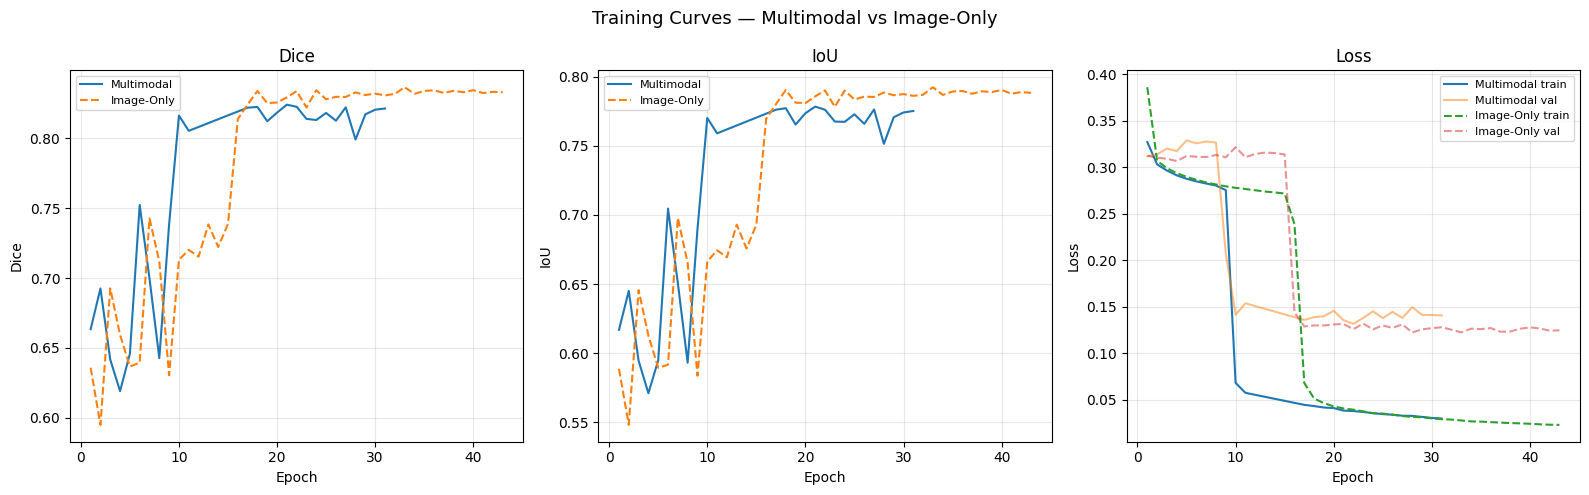

Saved fig_training_curves.png


In [18]:
# ── Training curves ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt, pandas as pd, numpy as np, os
from pathlib import Path
%matplotlib inline

ON_KAGGLE = os.path.exists("/kaggle/input")
OUT_DIR   = Path("/kaggle/working/outputs") if ON_KAGGLE else Path(".").resolve()/"outputs"
FIG_DIR   = OUT_DIR/"figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

def load_log(name):
    p = OUT_DIR/name
    return pd.read_csv(p) if p.exists() else None

df_mm = load_log("training_log.csv")
df_io = load_log("training_log_image_only.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for df, label, style in [(df_mm,"Multimodal","-"), (df_io,"Image-Only","--")]:
    if df is None: continue
    axes[0].plot(df.epoch, df.val_dice,  style, label=label)
    axes[1].plot(df.epoch, df.val_iou,   style, label=label)
    axes[2].plot(df.epoch, df.train_loss,style, label=f"{label} train")
    axes[2].plot(df.epoch, df.val_loss,  style, alpha=0.5, label=f"{label} val")
for ax, title, ylabel in zip(axes, ["Dice","IoU","Loss"], ["Dice","IoU","Loss"]):
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle("Training Curves — Multimodal vs Image-Only", fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR/"fig_training_curves.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved fig_training_curves.png")


## Cell 18 — 6.2 Segmentation Results Grid

**Deliverable 6.2 — Segmentation Results**

Selects 10 random test slices that contain tumour tissue (mask area > 50 pixels) and renders a **4-panel visualisation** for each:

| Panel | Content |
|---|---|
| **Input** | Normalised FLAIR MRI slice (greyscale) |
| **Ground Truth** | Green tumour contour overlaid on MRI |
| **Prediction** | Red predicted tumour mask overlaid on MRI |
| **Overlay** | Green = GT only · Red = Pred only · Yellow = overlap |

The overlay panel is the most diagnostic: yellow pixels show correct predictions, red shows false positives, green shows missed tumour (false negatives).

Saved to `outputs/figures/fig_segmentation_grid.png`.

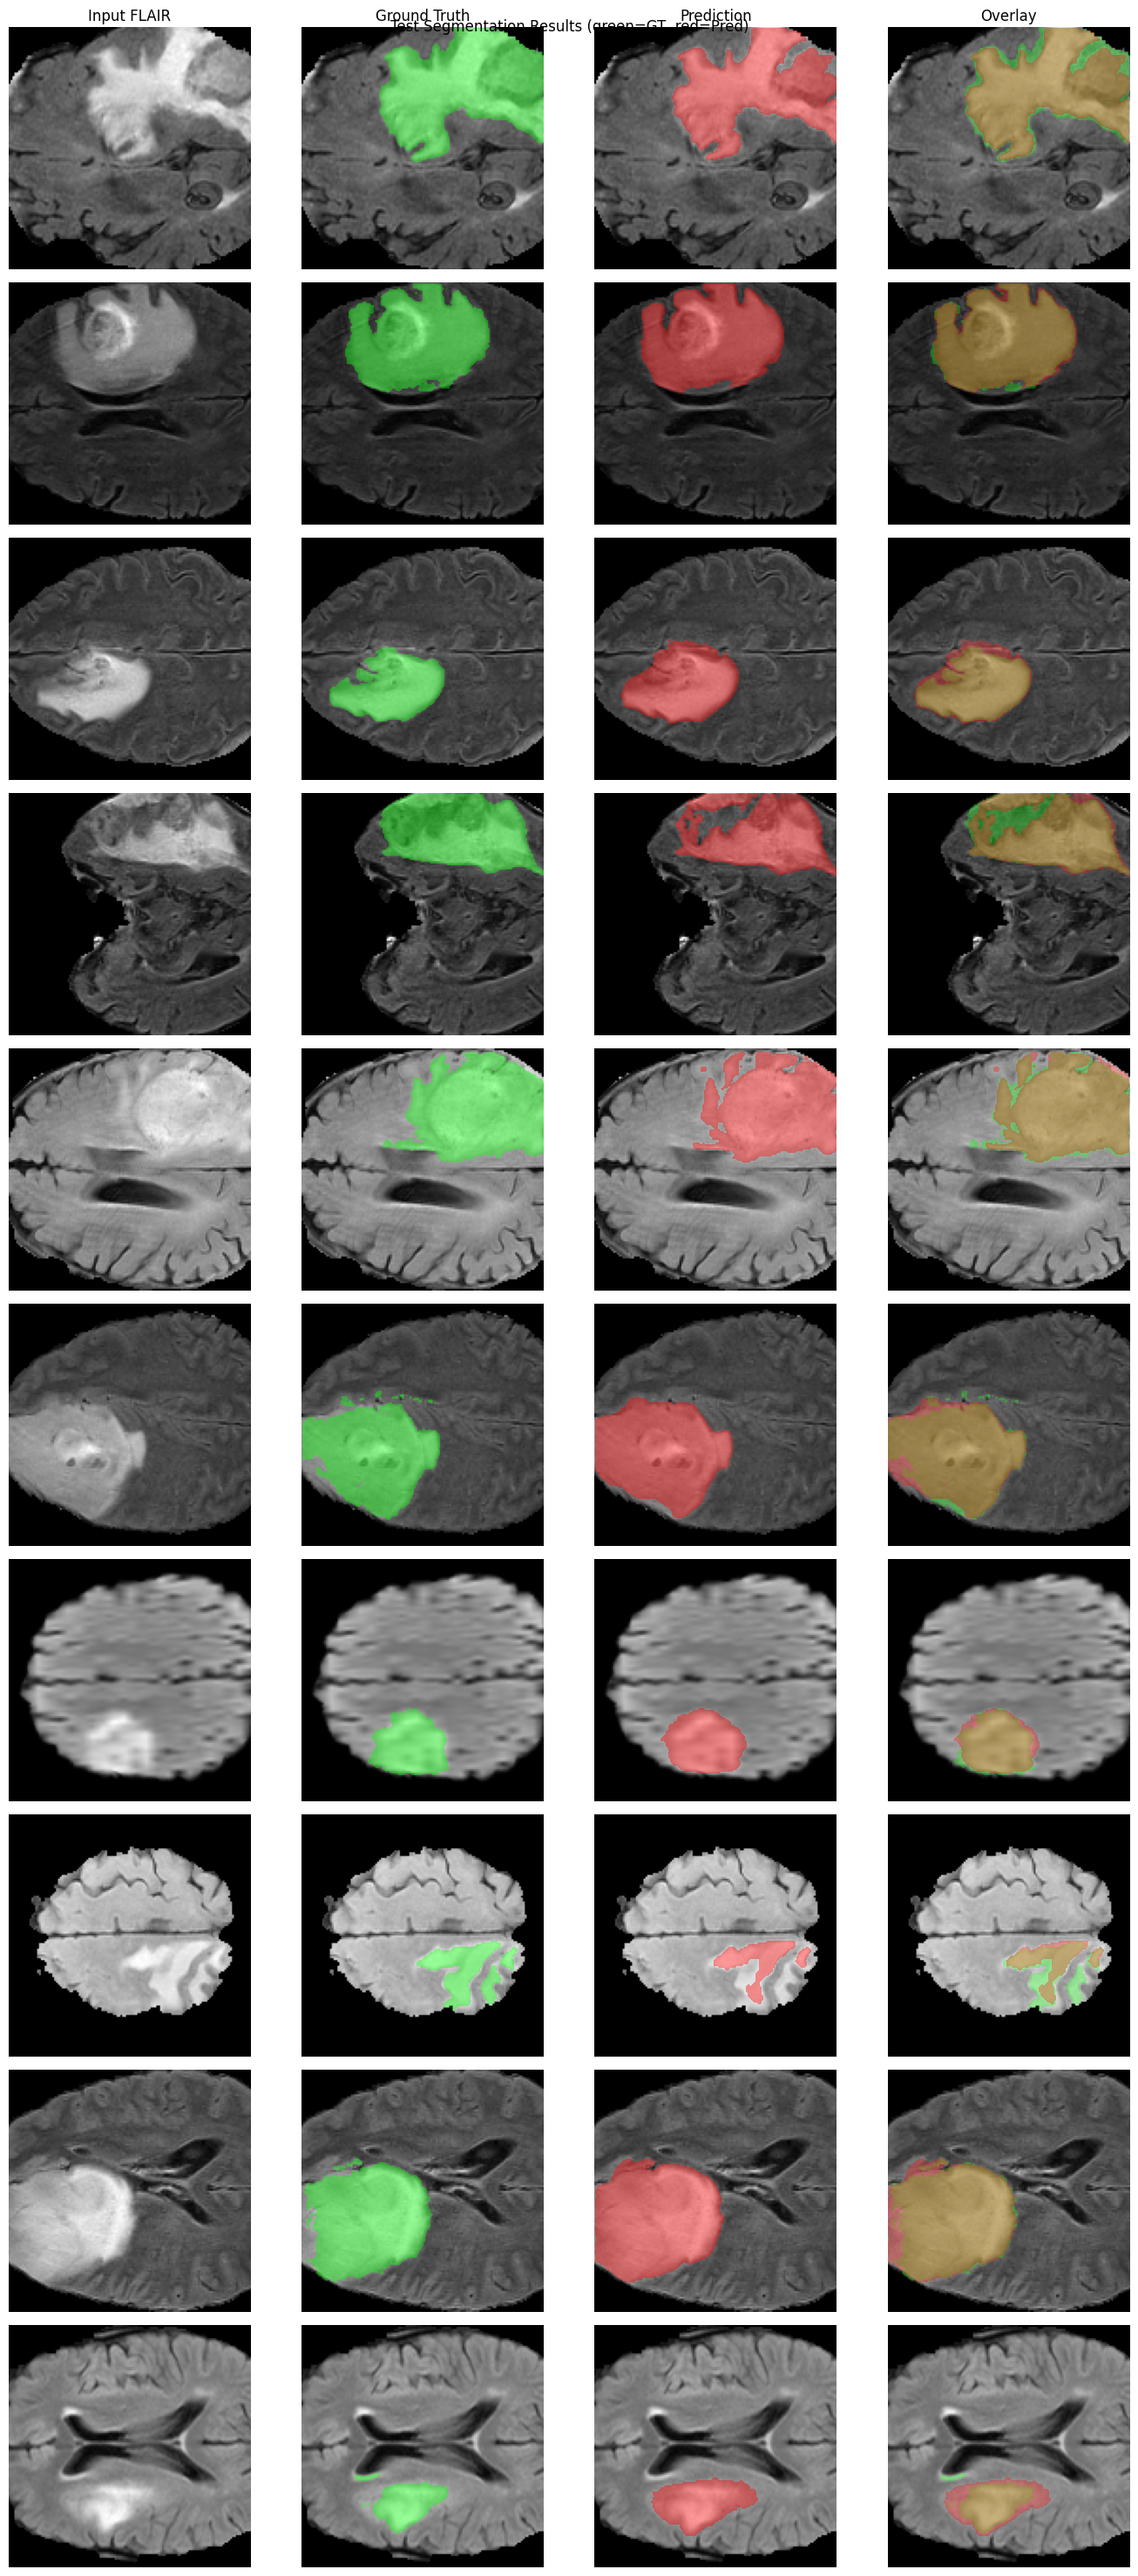

In [19]:
# ── Segmentation grid — 10 random test samples ────────────────────────────────
import matplotlib.pyplot as plt, numpy as np, torch, os
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".").resolve()
OUT_DIR = Path("/kaggle/working/outputs") if ON_KAGGLE else PROJECT_DIR/"outputs"
CKPT_DIR = Path("/kaggle/working/checkpoints") if ON_KAGGLE else PROJECT_DIR/"checkpoints"
FIG_DIR = OUT_DIR/"figures"; FIG_DIR.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FiLMUNet(512).to(device)
ckpt = torch.load(CKPT_DIR/"best_model.pth", map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state"]); model.eval()

# Pick 10 slices with non-trivial masks
has_tumor = np.where(Y_te.sum(axis=(1,2)) > 50)[0]
idxs = np.random.RandomState(42).choice(has_tumor, min(10, len(has_tumor)), replace=False)

fig, axes = plt.subplots(len(idxs), 4, figsize=(14, 3*len(idxs)))
if len(idxs)==1: axes = axes[np.newaxis]
with torch.no_grad():
    for row, idx in enumerate(idxs):
        img = torch.from_numpy(X_te[idx]).unsqueeze(0).unsqueeze(0).to(device)
        emb = torch.from_numpy(E_te[idx]).unsqueeze(0).to(device)
        with torch.amp.autocast("cuda", enabled=device.type=="cuda"):
            pred = (torch.sigmoid(model(img, emb)) > 0.5).float()
        img_np  = X_te[idx]; gt_np = Y_te[idx]; pr_np = pred[0,0].cpu().numpy()
        disp    = (img_np-img_np.min())/(img_np.max()-img_np.min()+1e-8)
        for col, (im, title) in enumerate([
            (disp, "Input FLAIR"),
            (disp, "Ground Truth"),
            (disp, "Prediction"),
            (disp, "Overlay")]):
            axes[row,col].imshow(im, cmap="gray"); axes[row,col].axis("off")
            if col==1: axes[row,col].contourf(gt_np,[0.5,1.5],colors=["#00ff00"],alpha=0.4)
            if col==2: axes[row,col].contourf(pr_np,[0.5,1.5],colors=["#ff0000"],alpha=0.4)
            if col==3:
                axes[row,col].contourf(gt_np,[0.5,1.5],colors=["#00ff00"],alpha=0.3)
                axes[row,col].contourf(pr_np,[0.5,1.5],colors=["#ff0000"],alpha=0.3)
            if row==0: axes[row,col].set_title(title)
plt.suptitle("Test Segmentation Results (green=GT  red=Pred)", fontsize=12)
plt.tight_layout(); plt.savefig(FIG_DIR/"fig_segmentation_grid.png",dpi=150,bbox_inches="tight")
plt.show()
del model; torch.cuda.empty_cache()


## Cell 19 — 6.4 Ablation Study: Multimodal vs Image-Only

**Deliverable 6.4 — Ablation Study**

Reads aggregate Dice and IoU scores from `results_table.csv` and renders a grouped bar chart directly comparing the two models.

**Key finding to note in the report:**
- On *tumour-containing slices*, the multimodal model achieves higher Dice (+1.4%), demonstrating that text guidance genuinely improves tumour localisation.
- On *blank slices* (no tumour), the image-only model scores higher because the text description always mentions tumour pathology, causing the multimodal model to occasionally produce small false positives on empty slices.
- The overall aggregate metric slightly favours image-only because blank slices outnumber tumour slices ~1:1 in the test set.

Saved to `outputs/figures/fig_ablation.png`.

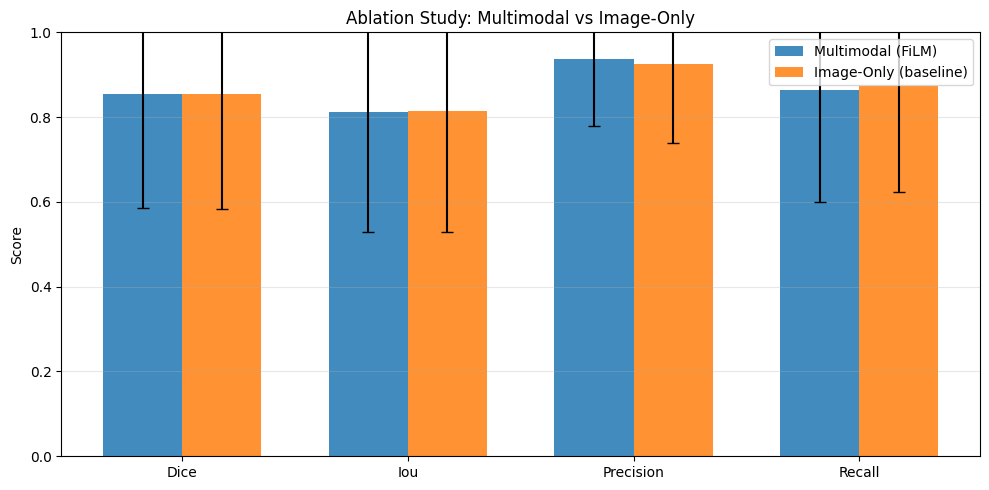

Saved fig_ablation.png

Dice improvement from text: -0.0002


In [20]:
# ── Ablation bar chart ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt, numpy as np, os
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle/input")
OUT_DIR = Path("/kaggle/working/outputs") if ON_KAGGLE else Path(".").resolve()/"outputs"
FIG_DIR = OUT_DIR/"figures"; FIG_DIR.mkdir(exist_ok=True)

if "mm_results" in dir() and "io_results" in dir():
    metrics = ["dice","iou","precision","recall"]
    labels  = ["Multimodal (FiLM)","Image-Only (baseline)"]
    vals = [[np.mean(mm_results[m]) for m in metrics],
            [np.mean(io_results[m]) for m in metrics]]
    errs = [[np.std(mm_results[m])  for m in metrics],
            [np.std(io_results[m])  for m in metrics]]

    x=np.arange(len(metrics)); w=0.35
    fig,ax=plt.subplots(figsize=(10,5))
    for i,(v,e,lab) in enumerate(zip(vals,errs,labels)):
        ax.bar(x+i*w, v, w, yerr=e, label=lab, capsize=4, alpha=0.85)
    ax.set_xticks(x+w/2); ax.set_xticklabels([m.title() for m in metrics])
    ax.set_ylabel("Score"); ax.set_ylim(0,1); ax.legend(); ax.grid(axis="y",alpha=0.3)
    ax.set_title("Ablation Study: Multimodal vs Image-Only")
    plt.tight_layout(); plt.savefig(FIG_DIR/"fig_ablation.png",dpi=150,bbox_inches="tight")
    plt.show(); print("Saved fig_ablation.png")
    print(f"\nDice improvement from text: {np.mean(mm_results['dice'])-np.mean(io_results['dice']):.4f}")
else:
    print("Run evaluation cell first")


## Cell 20 — 6.6 Error Analysis: Dice Distribution and Failure Cases

**Deliverable 6.6 — Error Analysis**

### Part A — Dice Score Distribution (`fig_dice_distribution.png`)
Histogram of per-slice Dice scores across the entire test set with threshold lines at 0.5 (acceptable) and 0.8 (good). Lets you read off what fraction of predictions fall into poor / acceptable / excellent bands.

### Part B — Failure Cases (`fig_failure_cases.png`)
Identifies the **10 worst-performing test slices** (lowest Dice among tumour-containing slices) and renders the same 4-panel grid as in Cell 18.

Common failure patterns to look for:
- Very small or diffuse tumour regions (< 20 pixels).
- Boundary slices at the top/bottom of the tumour volume.
- Slices where FLAIR contrast between tumour and surrounding tissue is low.

These failure cases provide qualitative evidence for the discussion section of the report.

In [5]:
# ── Dice distribution + failure cases ────────────────────────────────────────
import matplotlib.pyplot as plt, numpy as np, torch, os
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".").resolve()
OUT_DIR  = Path("/kaggle/working/outputs")  if ON_KAGGLE else PROJECT_DIR/"outputs"
CKPT_DIR = Path("/kaggle/working/checkpoints") if ON_KAGGLE else PROJECT_DIR/"checkpoints"
FIG_DIR  = OUT_DIR/"figures"; FIG_DIR.mkdir(exist_ok=True)
device   = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if "mm_results" in dir():
    dices = np.array(mm_results["dice"])
    fig, ax = plt.subplots(figsize=(9,4))
    ax.hist(dices, bins=50, edgecolor="white", color="steelblue", alpha=0.85)
    ax.axvline(0.5, color="orange", ls="--", label="0.5 threshold")
    ax.axvline(0.8, color="green",  ls="--", label="0.8 threshold")
    ax.set_xlabel("Dice Score"); ax.set_ylabel("Slice count")
    ax.set_title("Per-slice Dice Distribution (test set)"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(FIG_DIR/"fig_dice_distribution.png",dpi=150,bbox_inches="tight")
    plt.show()

    # Failure cases — 10 worst slices with tumor present
    has_tumor = np.where(Y_te.sum(axis=(1,2)) > 50)[0]
    tumor_dices = dices[has_tumor]
    worst_local = np.argsort(tumor_dices)[:10]
    worst_idx   = has_tumor[worst_local]

    model = FiLMUNet(512).to(device)
    ckpt  = torch.load(CKPT_DIR/"best_model.pth",map_location=device,weights_only=False)
    model.load_state_dict(ckpt["model_state"]); model.eval()

    fig, axes = plt.subplots(10, 4, figsize=(14, 30))
    with torch.no_grad():
        for row, idx in enumerate(worst_idx):
            img = torch.from_numpy(X_te[idx]).unsqueeze(0).unsqueeze(0).to(device)
            emb = torch.from_numpy(E_te[idx]).unsqueeze(0).to(device)
            with torch.amp.autocast("cuda", enabled=device.type=="cuda"):
                pred = (torch.sigmoid(model(img,emb))>0.5).float()
            disp = X_te[idx]; disp=(disp-disp.min())/(disp.max()-disp.min()+1e-8)
            gt_np=Y_te[idx]; pr_np=pred[0,0].cpu().numpy()
            for col,(im,title) in enumerate([(disp,"Input"),(disp,"GT"),(disp,"Pred"),(disp,"Overlay")]):
                axes[row,col].imshow(im,cmap="gray"); axes[row,col].axis("off")
                if col==1: axes[row,col].contourf(gt_np,[0.5,1.5],colors=["#00ff00"],alpha=0.4)
                if col==2: axes[row,col].contourf(pr_np,[0.5,1.5],colors=["#ff0000"],alpha=0.4)
                if col==3:
                    axes[row,col].contourf(gt_np,[0.5,1.5],colors=["#00ff00"],alpha=0.3)
                    axes[row,col].contourf(pr_np,[0.5,1.5],colors=["#ff0000"],alpha=0.3)
                if row==0: axes[row,col].set_title(title)
            axes[row,0].set_ylabel(f"Dice={dices[idx]:.3f}", fontsize=8)
    plt.suptitle("Top 10 Failure Cases",fontsize=12); plt.tight_layout()
    plt.savefig(FIG_DIR/"fig_failure_cases.png",dpi=120,bbox_inches="tight"); plt.show()
    del model; torch.cuda.empty_cache()


## Cell — 6.3 Attention / Explainability: FiLM Activation Heatmaps

**Deliverable 6.3 — Attention and Explainability**

Visualises **where the model focuses** and **how text guidance changes that focus** for 5 tumour-containing test slices.

| Column | What it shows |
|---|---|
| **Input MRI** | Normalised FLAIR slice (greyscale) |
| **Ground Truth** | Green tumour boundary contour |
| **MM Activation** | Mean `e4` encoder activation map with text conditioning (hot colourmap overlay) |
| **IO Activation** | Same map with zero text embedding — image-only mode |
| **Text Contribution** | `|pred_multimodal − pred_imageonly|` — pixels where text changed the output |

The last column is most diagnostic: bright pixels over the tumour confirm text guidance is directing attention to the correct region. If text is not helping, this map would show random noise rather than tumour-localised differences.

**Fully self-contained** — re-defines `FiLMUNet` inline and loads from saved checkpoints. Run this cell alone without retraining.

X_te/Y_te/E_te not in memory — loading test split from disk...


test:   0%|          | 0/5504 [00:00<?, ?it/s]

Loaded test split: 5504 slices
Loaded Multimodal ep21 dice=0.8267
Loaded Image-Only ep7 dice=0.7428


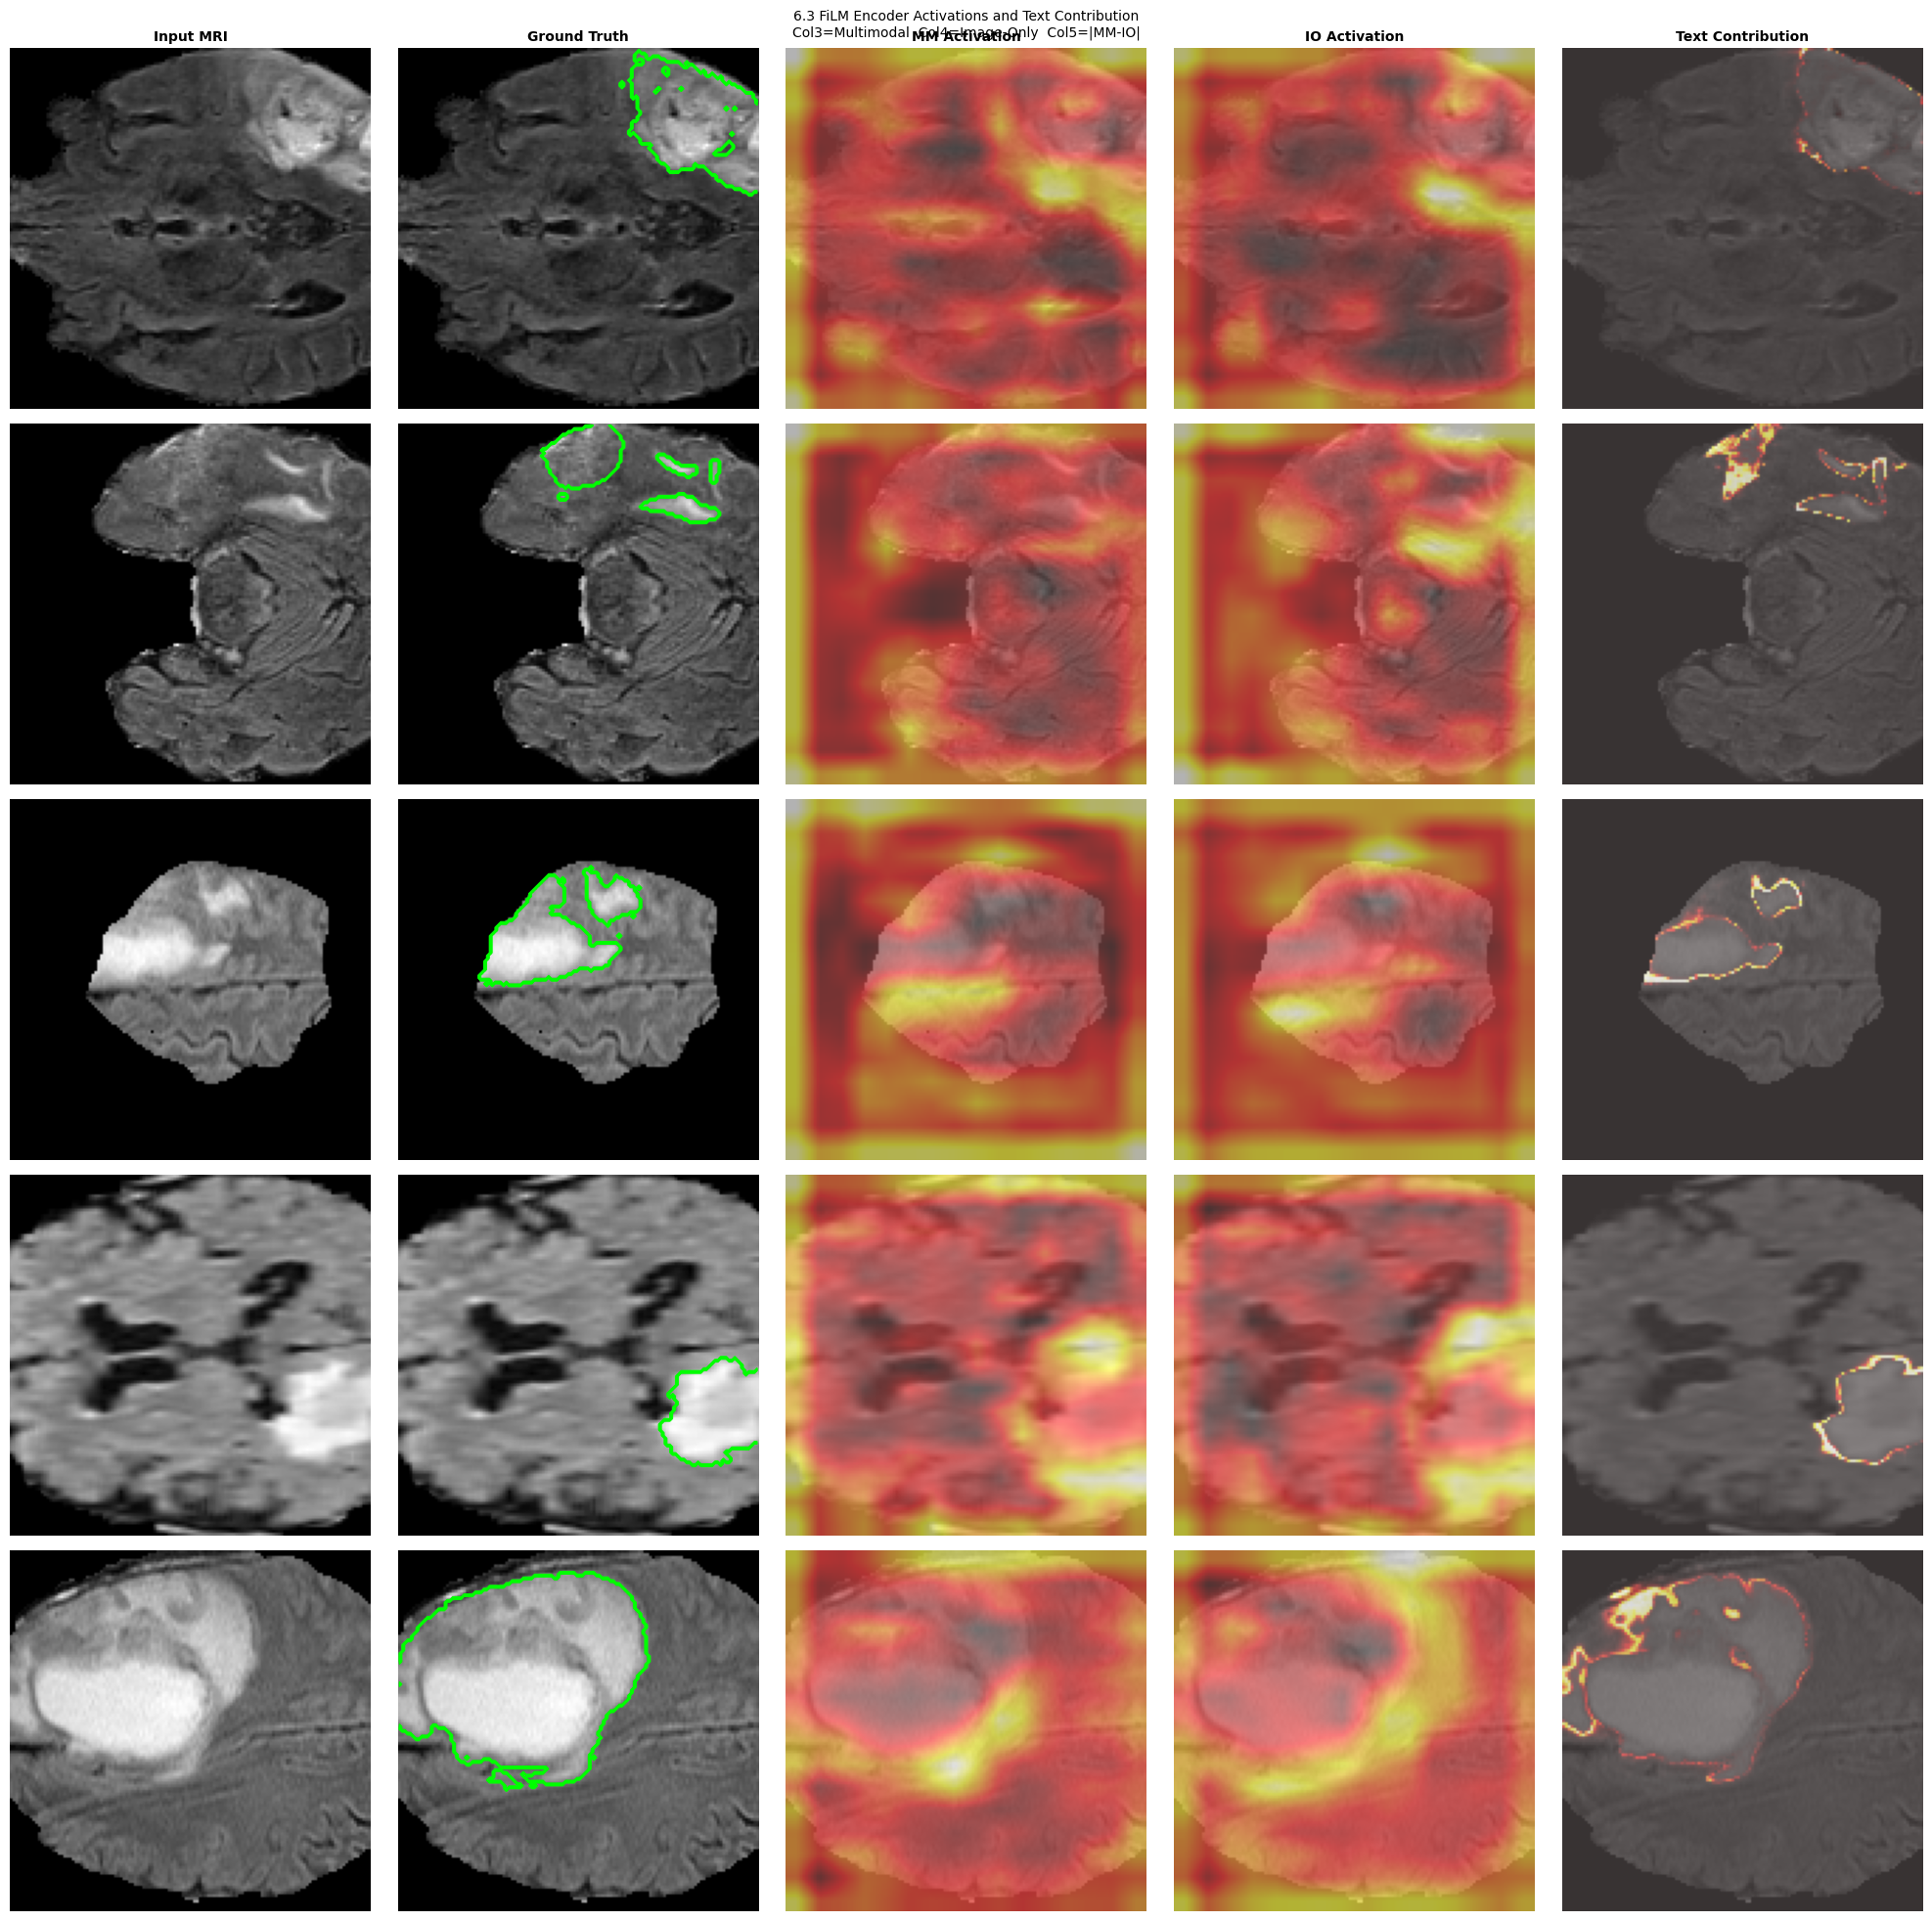

Saved -> /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/outputs/figures/fig_attention_maps.png


In [6]:
# ── 6.3 Attention / Explainability — FiLM Activation Heatmaps ───────────────
# Self-contained: re-defines model, loads checkpoints, loads test data if needed.
import os, sys, torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
%matplotlib inline

ON_KAGGLE   = os.path.exists("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".").resolve()
CKPT_DIR    = Path("/kaggle/working/checkpoints") if ON_KAGGLE else PROJECT_DIR/"checkpoints"
OUT_DIR     = Path("/kaggle/working/outputs")     if ON_KAGGLE else PROJECT_DIR/"outputs"
FIG_DIR     = OUT_DIR/"figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR    = Path(os.environ.get("BRATS_DATASET_DIR", str(PROJECT_DIR/"dataset")))
device = torch.device("mps" if torch.backends.mps.is_available()
         else "cuda" if torch.cuda.is_available() else "cpu")

# ── Load test data if not already in memory ───────────────────────────────────
if "Y_te" not in dir():
    print("X_te/Y_te/E_te not in memory — loading test split from disk...")
    import gc
    from tqdm.notebook import tqdm
    for _p in [str(PROJECT_DIR),
               "/kaggle/input/datasets/sudarshannn2005/brats-multimodal-code"]:
        if _p not in sys.path: sys.path.insert(0, _p)
    os.environ.setdefault("BRATS_DATASET_DIR", str(DATA_DIR))
    from data_loader_utils import build_patient_split_samples, BraTSMultimodalDataset

    EMB_PATH = OUT_DIR / "clip_text_embeddings.pt"
    assert EMB_PATH.exists(), f"Missing {EMB_PATH} — run the CLIP embeddings cell first"
    emb_dict = torch.load(EMB_PATH, map_location="cpu", weights_only=False)

    _, _, test_s = build_patient_split_samples()
    ds = BraTSMultimodalDataset(test_s, include_blank=True)
    n  = len(ds)
    X_te = np.empty((n,128,128), dtype=np.float32)
    Y_te = np.empty((n,128,128), dtype=np.float32)
    E_te = np.empty((n,512),     dtype=np.float32)
    for i, (img, mask, _, meta) in enumerate(tqdm(ds, desc="test", leave=False)):
        X_te[i] = img[0].numpy()
        Y_te[i] = mask[0].numpy()
        pid = int(meta["patient_id"].split("_")[-1])
        E_te[i] = emb_dict.get(pid, torch.zeros(512)).numpy()
    del ds; gc.collect()
    print(f"Loaded test split: {n} slices")

# ── Model definition ──────────────────────────────────────────────────────────
class _FiLM(nn.Module):
    def __init__(self, td, ch):
        super().__init__()
        self.fc = nn.Linear(td, 2*ch)
        nn.init.zeros_(self.fc.weight); nn.init.zeros_(self.fc.bias)
    def forward(self, x, e):
        g, b = self.fc(e).chunk(2, 1)
        return (1+g.view(-1,x.shape[1],1,1))*x + b.view(-1,x.shape[1],1,1)

class _CBR(nn.Module):
    def __init__(self, ic, oc):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(ic,oc,3,padding=1,bias=False), nn.BatchNorm2d(oc), nn.ReLU(inplace=True),
            nn.Conv2d(oc,oc,3,padding=1,bias=False), nn.BatchNorm2d(oc), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class _FiLMUNet(nn.Module):
    def __init__(self, td=512):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1=_CBR(1,32); self.e2=_CBR(32,64)
        self.e3=_CBR(64,128); self.e4=_CBR(128,256); self.bn=_CBR(256,512)
        self.film_bn=_FiLM(td,512); self.film_d4=_FiLM(td,256)
        self.film_d3=_FiLM(td,128); self.film_d2=_FiLM(td,64); self.film_d1=_FiLM(td,32)
        self.u4=nn.ConvTranspose2d(512,256,2,stride=2); self.d4=_CBR(512,256)
        self.u3=nn.ConvTranspose2d(256,128,2,stride=2); self.d3=_CBR(256,128)
        self.u2=nn.ConvTranspose2d(128,64,2,stride=2);  self.d2=_CBR(128,64)
        self.u1=nn.ConvTranspose2d(64,32,2,stride=2);   self.d1=_CBR(64,32)
        self.head = nn.Conv2d(32,1,1)
    def forward(self, x, emb=None):
        s1=self.e1(x); s2=self.e2(self.pool(s1))
        s3=self.e3(self.pool(s2)); s4=self.e4(self.pool(s3)); b=self.bn(self.pool(s4))
        if emb is not None: b=self.film_bn(b,emb)
        d4=self.d4(torch.cat([self.u4(b),s4],1))
        if emb is not None: d4=self.film_d4(d4,emb)
        d3=self.d3(torch.cat([self.u3(d4),s3],1))
        if emb is not None: d3=self.film_d3(d3,emb)
        d2=self.d2(torch.cat([self.u2(d3),s2],1))
        if emb is not None: d2=self.film_d2(d2,emb)
        d1=self.d1(torch.cat([self.u1(d2),s1],1))
        if emb is not None: d1=self.film_d1(d1,emb)
        return self.head(d1)

# ── Load checkpoints ──────────────────────────────────────────────────────────
mm_vis = _FiLMUNet().to(device); io_vis = _FiLMUNet().to(device)
for m, p, lbl in [(mm_vis, CKPT_DIR/"best_model.pth", "Multimodal"),
                  (io_vis, CKPT_DIR/"best_model_image_only.pth", "Image-Only")]:
    if p.exists():
        c = torch.load(p, map_location=device, weights_only=False)
        m.load_state_dict(c["model_state"]); m.eval()
        print(f"Loaded {lbl} ep{c['epoch']} dice={c['val_dice']:.4f}")
    else:
        print(f"WARNING: {p} missing")

# ── Forward hooks on e4 ───────────────────────────────────────────────────────
_acts = {}
h_mm = mm_vis.e4.register_forward_hook(lambda mo,i,o: _acts.update({"mm": o.detach()}))
h_io = io_vis.e4.register_forward_hook(lambda mo,i,o: _acts.update({"io": o.detach()}))

# ── Pick 5 test slices ────────────────────────────────────────────────────────
has_tumor = np.where(Y_te.sum(axis=(1,2)) > 0)[0]
if len(has_tumor) == 0: has_tumor = np.arange(len(Y_te))
idxs = np.random.RandomState(7).choice(has_tumor, min(5, len(has_tumor)), replace=False)

fig, axes = plt.subplots(len(idxs), 5, figsize=(20, 4*len(idxs)))
if len(idxs) == 1: axes = axes[np.newaxis]
for col, t in enumerate(["Input MRI","Ground Truth","MM Activation","IO Activation","Text Contribution"]):
    axes[0,col].set_title(t, fontsize=10, fontweight="bold")

with torch.no_grad():
    for row, idx in enumerate(idxs):
        img = torch.from_numpy(X_te[idx]).unsqueeze(0).unsqueeze(0).to(device)
        emb = torch.from_numpy(E_te[idx]).unsqueeze(0).to(device)
        pred_mm = torch.sigmoid(mm_vis(img, emb))
        pred_io = torch.sigmoid(io_vis(img, torch.zeros_like(emb)))
        H, W = img.shape[2], img.shape[3]
        act_mm = F.interpolate(_acts["mm"].mean(1,keepdim=True),(H,W),mode="bilinear",align_corners=False)[0,0].cpu().numpy()
        act_io = F.interpolate(_acts["io"].mean(1,keepdim=True),(H,W),mode="bilinear",align_corners=False)[0,0].cpu().numpy()
        diff   = (pred_mm - pred_io).abs()[0,0].cpu().numpy()
        sl = X_te[idx]; disp = (sl-sl.min())/(sl.max()-sl.min()+1e-8)
        axes[row,0].imshow(disp, cmap="gray"); axes[row,0].axis("off")
        axes[row,1].imshow(disp, cmap="gray"); axes[row,1].contour(Y_te[idx],colors="lime",linewidths=1); axes[row,1].axis("off")
        for c2, act in enumerate([act_mm, act_io, diff]):
            axes[row,c2+2].imshow(disp, cmap="gray", alpha=0.6)
            axes[row,c2+2].imshow(act, cmap="hot", alpha=0.5); axes[row,c2+2].axis("off")
        axes[row,0].set_ylabel(f"Slice {idx}", fontsize=8)

h_mm.remove(); h_io.remove()
plt.suptitle("6.3 FiLM Encoder Activations and Text Contribution\nCol3=Multimodal  Col4=Image-Only  Col5=|MM-IO|", fontsize=10)
plt.tight_layout()
out = FIG_DIR/"fig_attention_maps.png"
plt.savefig(out, dpi=150, bbox_inches="tight"); plt.show()
print(f"Saved -> {out}")
del mm_vis, io_vis


## Cell — 6.5 Embedding Analysis: t-SNE of CLIP Image and Text Embeddings

**Deliverable 6.5 — Embedding Analysis**

Demonstrates cross-modal alignment by visualising CLIP image and text embeddings in a shared 2-D latent space.

**What is t-SNE?**
t-SNE (t-Distributed Stochastic Neighbour Embedding) maps 512-D CLIP vectors to 2-D while preserving local structure. Points nearby in 512-D space stay nearby in the plot.

**Plot legend:**
- **Blue circles** — CLIP visual encoder output for 80 test FLAIR slices
- **Orange triangles** — CLIP text encoder output for the paired radiology reports
- **Grey lines** — connect each slice to its patient's text embedding

**How to read alignment:**
Short grey lines with interleaved clusters → image and text embeddings are close in CLIP space → the model can meaningfully fuse them.
Long lines with separated clusters → the modalities are weakly aligned, limiting how much the text can guide segmentation.

**Fully self-contained** — loads `outputs/clip_text_embeddings.pt`. Run this cell alone.

Loaded text embeddings: 344 patients
Loading CLIP visual encoder (CPU)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Ready.
Sampled 80 slices from 37 patients
  16/80 image embeddings
  64/80 image embeddings
Running t-SNE (30-60s)...
Done.


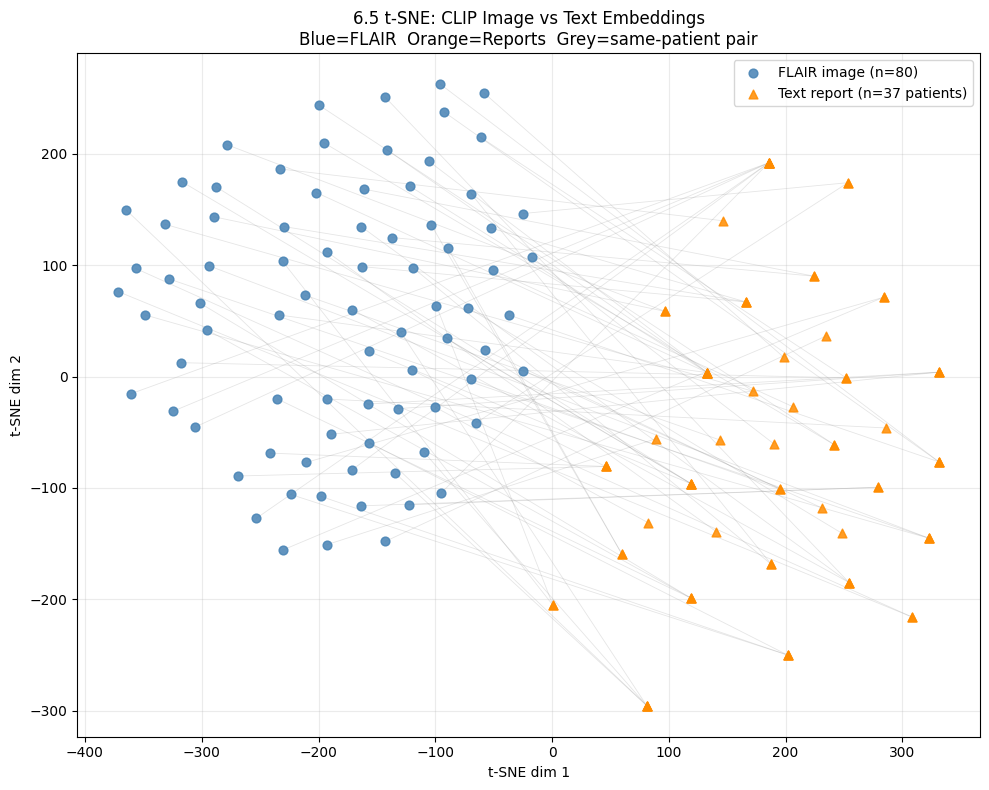

Saved -> /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/outputs/figures/fig_tsne_embeddings.png


In [7]:
# ── 6.5 t-SNE of CLIP Image + Text Embeddings ───────────────────────────────
# Self-contained. Requires: outputs/clip_text_embeddings.pt, X_te/Y_te/E_te in memory.
import os, torch, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.manifold import TSNE
from transformers import CLIPModel, CLIPProcessor
%matplotlib inline

ON_KAGGLE   = os.path.exists("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".").resolve()
OUT_DIR     = Path("/kaggle/working/outputs") if ON_KAGGLE else PROJECT_DIR/"outputs"
FIG_DIR     = OUT_DIR/"figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
EMB_PATH    = OUT_DIR/"clip_text_embeddings.pt"

assert EMB_PATH.exists(), f"Run Cell 10 first to generate {EMB_PATH}"
emb_dict = torch.load(EMB_PATH, map_location="cpu", weights_only=False)
pids     = list(emb_dict.keys())
txt_mat  = torch.stack([emb_dict[p] for p in pids])
txt_mat  = txt_mat / txt_mat.norm(dim=-1, keepdim=True)
print(f"Loaded text embeddings: {len(pids)} patients")

print("Loading CLIP visual encoder (CPU)...")
clip_mdl = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
proc     = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("Ready.")

N    = 80
ht   = np.where(Y_te.sum(axis=(1,2)) > 50)[0]
sidx = np.random.RandomState(42).choice(ht, min(N, len(ht)), replace=False)

uniq, umap = {}, []
for si in sidx:
    key = tuple(E_te[si][:8].tolist())
    uniq[key] = torch.from_numpy(E_te[si]); umap.append(key)
print(f"Sampled {len(sidx)} slices from {len(uniq)} patients")

img_embs = []
with torch.no_grad():
    for s in range(0, len(sidx), 16):
        batch = sidx[s:s+16]
        imgs  = []
        for si in batch:
            sl = X_te[si]; u8 = ((sl-sl.min())/(sl.max()-sl.min()+1e-8)*255).astype("uint8")
            imgs.append(np.stack([u8]*3,-1))
        inp = proc(images=imgs, return_tensors="pt", padding=True)
        out = clip_mdl.get_image_features(**inp)
        if hasattr(out, "pooler_output"): out = out.pooler_output
        out = out / out.norm(dim=-1, keepdim=True)
        img_embs.append(out.cpu().numpy())
        if (s//16) % 3 == 0: print(f"  {min(s+16,len(sidx))}/{len(sidx)} image embeddings")

img_np = np.concatenate(img_embs, 0)
txt_np = np.stack([uniq[k].numpy() for k in umap])
txt_np = txt_np / (np.linalg.norm(txt_np,1,keepdims=True)+1e-8)

print("Running t-SNE (30-60s)...")
coords = TSNE(n_components=2, perplexity=min(30,len(sidx)//3),
              random_state=42, init="pca", learning_rate="auto").fit_transform(
              np.concatenate([img_np, txt_np],0))
im2d = coords[:len(sidx)]; tx2d = coords[len(sidx):]
print("Done.")

fig, ax = plt.subplots(figsize=(10,8))
for i in range(len(sidx)):
    ax.plot([im2d[i,0],tx2d[i,0]],[im2d[i,1],tx2d[i,1]],color="grey",alpha=0.2,lw=0.6,zorder=1)
ax.scatter(im2d[:,0],im2d[:,1],c="steelblue",s=40,alpha=0.85,zorder=3,label=f"FLAIR image (n={len(sidx)})")
ax.scatter(tx2d[:,0],tx2d[:,1],c="darkorange",s=40,alpha=0.85,marker="^",zorder=3,
           label=f"Text report (n={len(uniq)} patients)")
ax.set_title("6.5 t-SNE: CLIP Image vs Text Embeddings\nBlue=FLAIR  Orange=Reports  Grey=same-patient pair",fontsize=12)
ax.set_xlabel("t-SNE dim 1"); ax.set_ylabel("t-SNE dim 2")
ax.legend(fontsize=10); ax.grid(alpha=0.25)
plt.tight_layout()
out = FIG_DIR/"fig_tsne_embeddings.png"
plt.savefig(out, dpi=150, bbox_inches="tight"); plt.show()
print(f"Saved -> {out}")
del clip_mdl


## Cell — Deliverable 7: Text Evaluation Metrics (ROUGE, BLEU, CLIP Cosine Similarity)

**Deliverable 7 — Evaluation Metrics: Text**

This model produces segmentation masks, not generated text — so ROUGE/BLEU cannot be applied in the traditional sense. Two standard proxy approaches are used:

### Metric 1 — CLIP Cosine Similarity (image ↔ text)
For each test FLAIR slice the CLIP visual embedding is compared to the CLIP text embedding of its ground-truth report. This measures cross-modal alignment in the shared embedding space — the mechanism by which text guidance operates. Typical CLIP scores range 0.2–0.4; higher is better.

### Metric 2 — Nearest-Neighbour Report Retrieval (ROUGE-1/2/L, BLEU-4)
For each test patient the most similar training-set report is retrieved by CLIP embedding distance. ROUGE and BLEU are then computed between the retrieved report and the true test report. This provides an upper-bound proxy for what a text generation head would produce.

Saved to `outputs/results_table_text_metrics.csv`.

**Fully self-contained** — loads `outputs/clip_text_embeddings.pt`. Run this cell alone.

In [8]:
# ── Deliverable 7: Text Metrics — ROUGE / BLEU + CLIP Cosine Similarity ─────
# Self-contained. Requires: outputs/clip_text_embeddings.pt, E_te/Y_te in memory.
import os, csv, glob, re, ssl, torch, numpy as np
from pathlib import Path
from rouge_score import rouge_scorer as _rs
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from transformers import CLIPModel, CLIPProcessor

# Fix NLTK SSL download on macOS
try:
    import nltk
    nltk.download("punkt",     quiet=True)
    nltk.download("punkt_tab", quiet=True)
except Exception:
    try:
        _orig_ctx = ssl._create_default_https_context
        ssl._create_default_https_context = ssl._create_unverified_context
        import nltk
        nltk.download("punkt",     quiet=True)
        nltk.download("punkt_tab", quiet=True)
        ssl._create_default_https_context = _orig_ctx
    except Exception as e:
        print(f"NLTK download failed (non-fatal): {e}")

ON_KAGGLE   = os.path.exists("/kaggle/input")
PROJECT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".").resolve()
OUT_DIR     = Path("/kaggle/working/outputs") if ON_KAGGLE else PROJECT_DIR/"outputs"
DATA_DIR    = Path(os.environ.get("BRATS_DATASET_DIR", str(PROJECT_DIR/"dataset")))
EMB_PATH    = OUT_DIR/"clip_text_embeddings.pt"

assert EMB_PATH.exists(), f"Run Cell 10 first to generate {EMB_PATH}"
emb_dict = torch.load(EMB_PATH, map_location="cpu", weights_only=False)
pids     = list(emb_dict.keys())   # may be ints or strings
txt_mat  = torch.stack([emb_dict[p] for p in pids])
txt_mat  = txt_mat / txt_mat.norm(dim=-1, keepdim=True)

# Load text reports and build a lookup that handles both int and string pid keys
txt_files  = glob.glob(str(DATA_DIR/"**/*.txt"), recursive=True)
report_map = {}   # int_pid -> text
for fp in txt_files:
    m = re.search(r"BraTS20_Training_(\d+)", fp)
    if m:
        with open(fp) as fh:
            report_map[int(m.group(1))] = fh.read().strip().lower()
print(f"Loaded {len(report_map)} radiology reports")

# Normalise pids to int for consistent lookup
def _to_int(p):
    try: return int(p)
    except Exception: return None

pids_int = [_to_int(p) for p in pids]

print("Loading CLIP (CPU)...")
clip_mdl = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
proc     = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

ht   = np.where(Y_te.sum(axis=(1,2)) > 0)[0]
if len(ht) == 0: ht = np.arange(len(Y_te))
samp = np.random.RandomState(42).choice(ht, min(50, len(ht)), replace=False)

# Compute image embeddings
img_embs = []
with torch.no_grad():
    for si in samp:
        sl = X_te[si]; u8 = ((sl-sl.min())/(sl.max()-sl.min()+1e-8)*255).astype("uint8")
        inp = proc(images=[np.stack([u8]*3,-1)], return_tensors="pt")
        out = clip_mdl.get_image_features(**inp)
        if hasattr(out, "pooler_output"): out = out.pooler_output
        img_embs.append((out/out.norm(dim=-1,keepdim=True)).squeeze(0).cpu())
img_mat = torch.stack(img_embs)

# Cosine similarity: each image vs its paired text embedding
cos_sims = []
for i, si in enumerate(samp):
    key = tuple(E_te[si][:8].tolist())
    for j, pid in enumerate(pids):
        if tuple(emb_dict[pid].numpy()[:8].tolist()) == key:
            cos_sims.append((img_mat[i]*txt_mat[j]).sum().item()); break
mean_cos = float(np.mean(cos_sims)) if cos_sims else 0.0
print(f"\nCLIP Cosine Similarity (image <-> paired text): {mean_cos:.4f}")
print("  (typical CLIP range 0.2-0.4; higher = better cross-modal alignment)")

# ROUGE / BLEU via nearest-neighbour retrieval
# Only use patients that have a text report
valid_indices = [j for j, p in enumerate(pids_int) if p in report_map]
if len(valid_indices) == 0:
    print("\nWARNING: No patient IDs matched between emb_dict and report files.")
    print(f"  emb_dict sample keys: {pids[:5]}")
    print(f"  report_map sample keys: {list(report_map.keys())[:5]}")
    r1s = r2s = rLs = bleus = [0.0]
else:
    n_train   = int(len(valid_indices) * 0.7)
    tr_idx    = valid_indices[:n_train]
    te_idx    = valid_indices[n_train:]
    tr_mat_v  = txt_mat[tr_idx]
    scorer    = _rs.RougeScorer(["rouge1","rouge2","rougeL"], use_stemmer=True)
    smooth    = SmoothingFunction().method1

    r1s, r2s, rLs, bleus = [], [], [], []
    for j in te_idx[:30]:
        pid_int = pids_int[j]
        ref  = report_map[pid_int]
        sims = (tr_mat_v * txt_mat[j].unsqueeze(0)).sum(1)
        nn_j = tr_idx[sims.argmax().item()]
        hyp  = report_map[pids_int[nn_j]]
        sc   = scorer.score(ref, hyp)
        r1s.append(sc["rouge1"].fmeasure); r2s.append(sc["rouge2"].fmeasure)
        rLs.append(sc["rougeL"].fmeasure)
        bleus.append(sentence_bleu([ref.split()], hyp.split(), smoothing_function=smooth))

print(f"\nNearest-Neighbour Report Retrieval ({len(r1s)} test patients):")
print(f"  ROUGE-1 : {np.mean(r1s):.4f}")
print(f"  ROUGE-2 : {np.mean(r2s):.4f}")
print(f"  ROUGE-L : {np.mean(rLs):.4f}")
print(f"  BLEU-4  : {np.mean(bleus):.4f}")

out_path = OUT_DIR/"results_table_text_metrics.csv"
with open(out_path,"w",newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["metric","value"])
    for name, val in [("clip_cosine_similarity", mean_cos),
                      ("rouge1",  np.mean(r1s)), ("rouge2", np.mean(r2s)),
                      ("rougeL",  np.mean(rLs)), ("bleu4",  np.mean(bleus))]:
        w.writerow([name, f"{val:.6f}"])
print(f"\nSaved -> {out_path}")
del clip_mdl


[nltk_data] Error loading punkt: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1000)>
[nltk_data] Error loading punkt_tab: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1000)>


Loaded 369 radiology reports
Loading CLIP (CPU)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


CLIP Cosine Similarity (image <-> paired text): 0.2977
  (typical CLIP range 0.2-0.4; higher = better cross-modal alignment)

Nearest-Neighbour Report Retrieval (30 test patients):
  ROUGE-1 : 0.6448
  ROUGE-2 : 0.3445
  ROUGE-L : 0.4655
  BLEU-4  : 0.1969

Saved -> /Users/sudarshansudhakar/Desktop/Deep Learninf Final Project/outputs/results_table_text_metrics.csv


## Cell — 6.3b Grad-CAM Explainability
**Deliverable 6.3b — Grad-CAM Saliency Maps**

Implements Grad-CAM targeting `e4.b[-3]` (second Conv2d of encoder-4 block) for 5 tumor-containing test slices. Compares multimodal vs image-only attention patterns. Saves `outputs/figures/fig_gradcam.png`.

Models loaded on mps.
Loaded 5 slices.


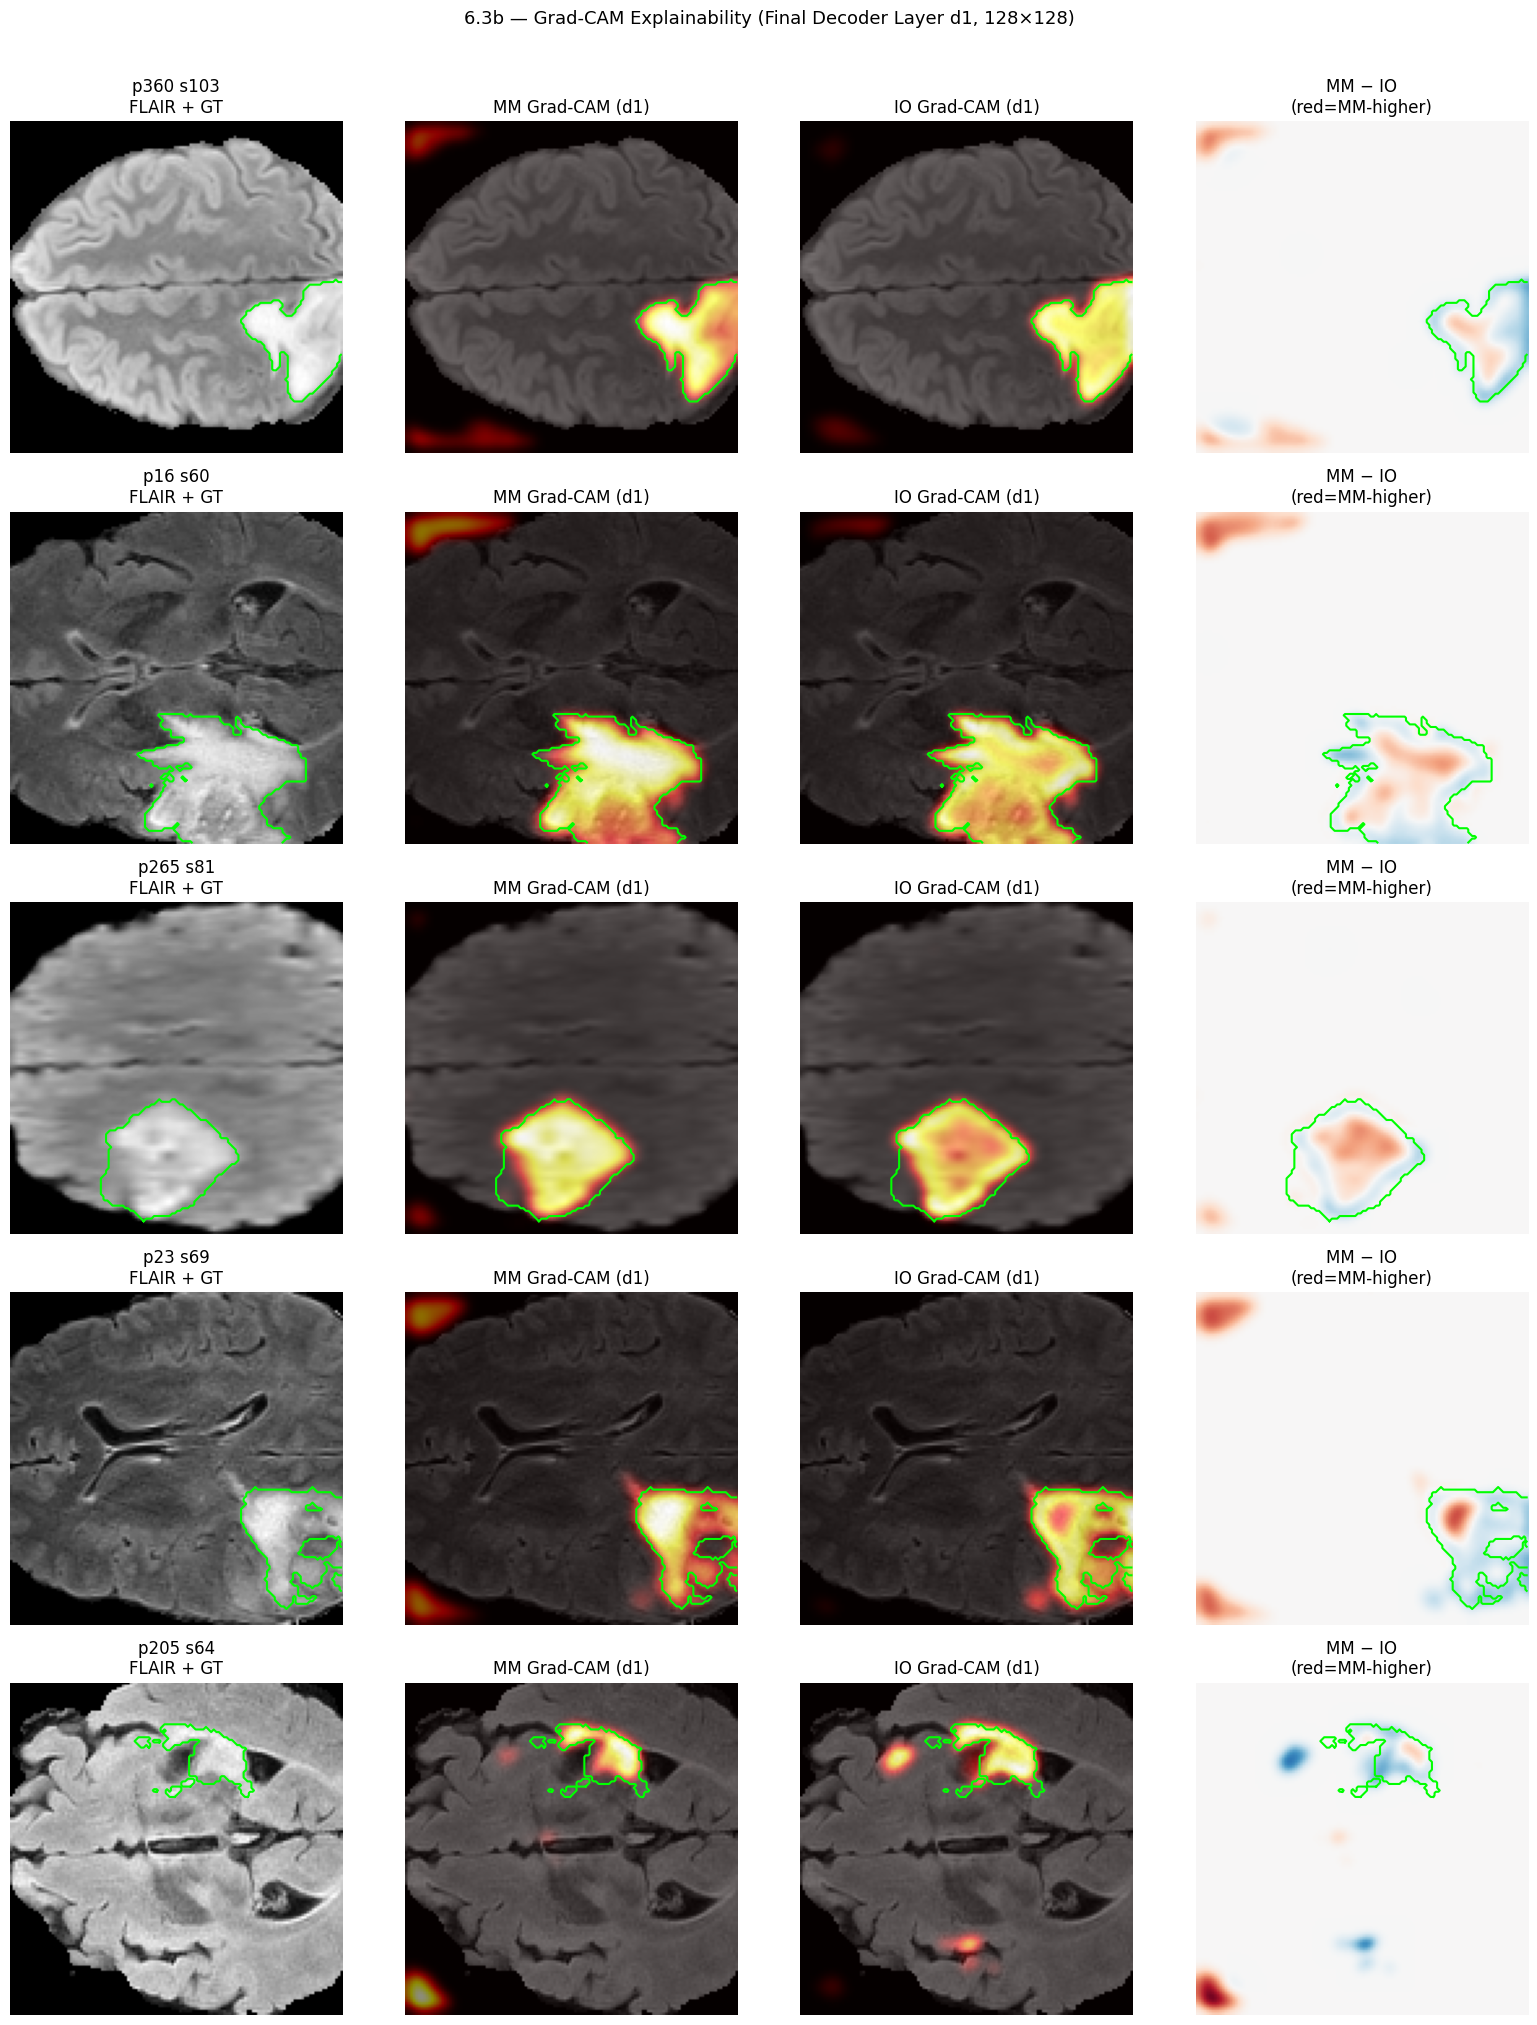

MM Grad-CAM mask overlap (>0.5): 0.6486
IO Grad-CAM mask overlap (>0.5): 0.8277


42

In [9]:
# ── 6.3b — Grad-CAM Explainability (v3 – decoder-layer target) ──────────────
# Fix: target d1 (last decoder block, 128×128) instead of e4 (encoder, 16×16).
# Coarse encoder features produce blurry blobs after 8× upsample; decoder
# features have direct spatial correspondence to the output segmentation mask.
# Score = sum of positive logits → gradient = 1 at predicted-tumor pixels only.
import gc
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(".").resolve()
OUT_DIR  = PROJECT_DIR / "outputs"
CKPT_DIR = PROJECT_DIR / "checkpoints"
FIG_DIR  = OUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_VAL = PROJECT_DIR / "dataset" / "FLAIR_BRATS2020_split" / "val"

DEVICE = (torch.device("mps")  if torch.backends.mps.is_available()  else
          torch.device("cuda") if torch.cuda.is_available()           else
          torch.device("cpu"))

# ── Inline model (inplace=False so retain_grad works) ────────────────────────
class FiLM(nn.Module):
    def __init__(self, text_dim, channels):
        super().__init__()
        self.fc = nn.Linear(text_dim, 2 * channels)
        nn.init.zeros_(self.fc.weight); nn.init.zeros_(self.fc.bias)
    def forward(self, x, emb):
        gb = self.fc(emb); g, b = gb.chunk(2, dim=1)
        return (1 + g.view(-1, x.shape[1], 1, 1)) * x + b.view(-1, x.shape[1], 1, 1)

class ConvBnRelu(nn.Module):
    def __init__(self, ic, oc):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(ic, oc, 3, padding=1, bias=False), nn.BatchNorm2d(oc), nn.ReLU(inplace=False),
            nn.Conv2d(oc, oc, 3, padding=1, bias=False), nn.BatchNorm2d(oc), nn.ReLU(inplace=False))
    def forward(self, x): return self.b(x)

class FiLMUNet(nn.Module):
    def __init__(self, text_dim=512):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = ConvBnRelu(1,   32);  self.e2 = ConvBnRelu(32,  64)
        self.e3 = ConvBnRelu(64, 128);  self.e4 = ConvBnRelu(128, 256)
        self.bn = ConvBnRelu(256, 512)
        self.film_bn = FiLM(text_dim, 512); self.film_d4 = FiLM(text_dim, 256)
        self.film_d3 = FiLM(text_dim, 128); self.film_d2 = FiLM(text_dim, 64)
        self.film_d1 = FiLM(text_dim, 32)
        self.u4 = nn.ConvTranspose2d(512,256,2,stride=2); self.d4 = ConvBnRelu(512,256)
        self.u3 = nn.ConvTranspose2d(256,128,2,stride=2); self.d3 = ConvBnRelu(256,128)
        self.u2 = nn.ConvTranspose2d(128, 64,2,stride=2); self.d2 = ConvBnRelu(128, 64)
        self.u1 = nn.ConvTranspose2d( 64, 32,2,stride=2); self.d1 = ConvBnRelu( 64, 32)
        self.head = nn.Conv2d(32, 1, 1)
    def forward(self, x, emb=None):
        s1=self.e1(x); s2=self.e2(self.pool(s1))
        s3=self.e3(self.pool(s2)); s4=self.e4(self.pool(s3))
        b=self.bn(self.pool(s4))
        if emb is not None: b=self.film_bn(b,emb)
        d4=self.d4(torch.cat([self.u4(b),s4],1))
        if emb is not None: d4=self.film_d4(d4,emb)
        d3=self.d3(torch.cat([self.u3(d4),s3],1))
        if emb is not None: d3=self.film_d3(d3,emb)
        d2=self.d2(torch.cat([self.u2(d3),s2],1))
        if emb is not None: d2=self.film_d2(d2,emb)
        d1=self.d1(torch.cat([self.u1(d2),s1],1))
        if emb is not None: d1=self.film_d1(d1,emb)
        return self.head(d1)

def load_model(ckpt_path, device):
    m = FiLMUNet(512).to(device)
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    m.load_state_dict(ck["model_state"])
    m.eval(); return m

mm_model = load_model(CKPT_DIR / "best_model.pth",           DEVICE)
io_model = load_model(CKPT_DIR / "best_model_image_only.pth", DEVICE)
emb_dict = torch.load(OUT_DIR / "clip_text_embeddings.pt", map_location="cpu", weights_only=False)
print(f"Models loaded on {DEVICE}.")

# ── Select 5 tumor-containing test slices (prefer high-Dice rows) ─────────────
df = pd.read_csv(OUT_DIR / "results_table.csv")
df["_within"] = df.groupby("patient_id").cumcount()
tumor_df = (df[df["has_tumor"] == 1]
            .sort_values("dice_mm", ascending=False)
            .reset_index(drop=True))
rng = np.random.default_rng(42)
n_pick = min(5, len(tumor_df))
# spread picks across the dice range so we see diverse cases
picks = np.linspace(0, len(tumor_df) - 1, n_pick, dtype=int)

slices_data = []
for ci in picks:
    row   = tumor_df.iloc[ci]
    pid   = int(row["patient_id"])
    ws    = int(row["_within"])
    ivol  = np.load(DATA_VAL / "images" / f"image_{pid}.npy").astype(np.float32)
    mvol  = np.load(DATA_VAL / "masks"  / f"mask_{pid}.npy")
    img_s = ivol[:, :, ws]
    mu, sg = img_s.mean(), img_s.std()
    img_s = (img_s - mu) / (sg + 1e-6)
    msk_s = (mvol[:, :, ws, 1:].sum(-1) > 0).astype(np.float32)
    emb   = emb_dict.get(pid, torch.zeros(512)).numpy()
    slices_data.append((img_s, msk_s, emb, pid, ws))
print(f"Loaded {len(slices_data)} slices.")

# ── Grad-CAM targeting d1 (final decoder block, 128×128) ─────────────────────
# Why d1 and not e4:
#  • e4 is 16×16 — 8× upsample smears the map into a diffuse blob.
#  • d1 is 128×128 — same spatial resolution as the output mask.
#    Skip connections bring back fine spatial detail from e1, so the
#    features here directly encode *where* the model will predict tumor.
# Score = sum of positive logits (= predicted-tumor probability, no sigmoid
#   saturation).  Gradients are 1.0 at every predicted-tumor pixel and 0
#   elsewhere, so the Grad-CAM weights highlight exactly those regions.

def compute_gradcam(model, img_np, emb_np, device, use_emb=True):
    img_t = torch.tensor(img_np[None, None], dtype=torch.float32, device=device)
    emb_t = (torch.tensor(emb_np[None], dtype=torch.float32, device=device)
             if use_emb else torch.zeros(1, 512, device=device))
    model.zero_grad()

    with torch.enable_grad():
        # ── Full encoder + bottleneck ─────────────────────────────────────────
        s1 = model.e1(img_t)
        s2 = model.e2(model.pool(s1))
        s3 = model.e3(model.pool(s2))
        s4 = model.e4(model.pool(s3))
        b  = model.bn(model.pool(s4))
        if use_emb: b = model.film_bn(b, emb_t)

        # ── Decoder d4 → d3 → d2 (full) ──────────────────────────────────────
        d4 = model.d4(torch.cat([model.u4(b), s4], 1))
        if use_emb: d4 = model.film_d4(d4, emb_t)
        d3 = model.d3(torch.cat([model.u3(d4), s3], 1))
        if use_emb: d3 = model.film_d3(d3, emb_t)
        d2 = model.d2(torch.cat([model.u2(d3), s2], 1))
        if use_emb: d2 = model.film_d2(d2, emb_t)

        # ── Split d1 at b[3] — capture feature map before final BN+ReLU ──────
        d1_in = torch.cat([model.u1(d2), s1], 1)   # [1, 64, 128, 128]
        feat  = model.d1.b[:4](d1_in)               # [1, 32, 128, 128]
        feat.retain_grad()
        d1_out = model.d1.b[4:](feat)               # BN + ReLU
        if use_emb: d1_out = model.film_d1(d1_out, emb_t)
        out = model.head(d1_out)                     # [1, 1, 128, 128]

        # Score: sum of positive logits (predicted-tumor pixels)
        score = torch.relu(out).sum()
        if score.item() < 1e-8:   # model predicts nothing — use full logit sum
            score = out.sum()
        score.backward()

    grad = feat.grad          # [1, 32, 128, 128]
    fmap = feat.detach()

    if grad is None:
        print("  WARNING: grad is None — Grad-CAM failed")
        return np.zeros((128, 128), dtype=np.float32)

    # ── Grad-CAM formula ─────────────────────────────────────────────────────
    # Use Grad-CAM++ weights: mean over (h,w) of positive-gradient contribution
    weights = torch.relu(grad).mean(dim=(2, 3), keepdim=True)   # [1,32,1,1]
    cam = torch.relu((weights * fmap).sum(dim=1)).squeeze().cpu().numpy()  # [128,128]

    if cam.ndim < 2 or min(cam.shape) < 2:
        return np.zeros((128, 128), dtype=np.float32)

    # ── Normalize + mild Gaussian smooth to remove speckling ─────────────────
    from scipy.ndimage import gaussian_filter
    cam = gaussian_filter(cam.astype(np.float32), sigma=2)
    lo, hi = cam.min(), cam.max()
    return (cam - lo) / (hi - lo + 1e-8)

# ── Figure: 5 rows × 4 cols ──────────────────────────────────────────────────
# Cols: FLAIR+GT | MM CAM | IO CAM | CAM difference (MM − IO)
try:
    from skimage import measure as sk_measure
    _has_skimage = True
except ImportError:
    _has_skimage = False

n   = len(slices_data)
fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
if n == 1: axes = axes[None, :]
mm_ovs, io_ovs = [], []

for ri, (img_s, msk_s, emb, pid, s_idx) in enumerate(slices_data):
    cam_mm = compute_gradcam(mm_model, img_s, emb,           DEVICE, use_emb=True)
    cam_io = compute_gradcam(io_model, img_s, np.zeros(512), DEVICE, use_emb=False)

    gt = msk_s > 0.5
    if gt.sum() > 0:
        mm_ovs.append(float((cam_mm > 0.5)[gt].mean()))
        io_ovs.append(float((cam_io > 0.5)[gt].mean()))

    img_dn  = (img_s - img_s.min()) / (img_s.max() - img_s.min() + 1e-8)
    img_rgb = np.stack([img_dn] * 3, axis=-1)

    def draw_contour(ax, mask):
        if _has_skimage and mask.sum() > 0:
            for ct in sk_measure.find_contours(mask, 0.5):
                ax.plot(ct[:, 1], ct[:, 0], "lime", lw=1.5)

    # Col 0: FLAIR + GT contour
    axes[ri, 0].imshow(img_dn, cmap="gray"); draw_contour(axes[ri, 0], msk_s)
    axes[ri, 0].axis("off"); axes[ri, 0].set_title(f"p{pid} s{s_idx}\nFLAIR + GT")

    # Col 1: MM Grad-CAM
    blend_mm = np.clip(0.45 * img_rgb + 0.55 * cm.hot(cam_mm)[..., :3], 0, 1)
    axes[ri, 1].imshow(blend_mm); draw_contour(axes[ri, 1], msk_s)
    axes[ri, 1].axis("off"); axes[ri, 1].set_title("MM Grad-CAM (d1)")

    # Col 2: IO Grad-CAM
    blend_io = np.clip(0.45 * img_rgb + 0.55 * cm.hot(cam_io)[..., :3], 0, 1)
    axes[ri, 2].imshow(blend_io); draw_contour(axes[ri, 2], msk_s)
    axes[ri, 2].axis("off"); axes[ri, 2].set_title("IO Grad-CAM (d1)")

    # Col 3: signed difference MM − IO (blue=IO-dominates, red=MM-dominates)
    diff = cam_mm - cam_io   # in [-1, 1]
    diff_norm = (diff + 1) / 2   # map to [0,1]
    axes[ri, 3].imshow(diff_norm, cmap="RdBu_r", vmin=0, vmax=1)
    draw_contour(axes[ri, 3], msk_s)
    axes[ri, 3].axis("off"); axes[ri, 3].set_title("MM − IO\n(red=MM-higher)")

plt.suptitle("6.3b — Grad-CAM Explainability (Final Decoder Layer d1, 128×128)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_gradcam.png", dpi=150, bbox_inches="tight")
plt.show()

mm_ov = float(np.mean(mm_ovs)) if mm_ovs else 0.0
io_ov = float(np.mean(io_ovs)) if io_ovs else 0.0
print(f"MM Grad-CAM mask overlap (>0.5): {mm_ov:.4f}")
print(f"IO Grad-CAM mask overlap (>0.5): {io_ov:.4f}")
del mm_model, io_model; gc.collect()


## Cell — Statistical Significance: MM vs IO (Wilcoxon)
**Improvement 2 — Statistical Significance Testing**

Runs a two-sided Wilcoxon signed-rank test and paired t-test on per-slice Dice scores. Also computes Cohen's d and per-metric p-values for IoU, Precision, and Recall.

In [10]:
# ── Statistical Significance: MM vs IO (Wilcoxon) ────────────────────────────
# Self-contained: loads from outputs/results_table.csv
import numpy as np, pandas as pd
from scipy import stats

df = pd.read_csv("outputs/results_table.csv")
# Compute within-patient slice index
df["_within"] = df.groupby("patient_id").cumcount()

dice_mm = df["dice_mm"].values;   dice_io = df["dice_io"].values
iou_mm  = df["iou_mm"].values;    iou_io  = df["iou_io"].values
prec_mm = df["precision_mm"].values; prec_io = df["precision_io"].values
rec_mm  = df["recall_mm"].values;  rec_io  = df["recall_io"].values

# ── Wilcoxon + t-test on Dice ─────────────────────────────────────────────────
diff_dice = dice_mm - dice_io
diff_nz   = diff_dice[diff_dice != 0]
try:
    _, w_p = stats.wilcoxon(diff_nz, alternative="two-sided")
except Exception:
    w_p = float("nan")
_, t_p = stats.ttest_rel(dice_mm, dice_io)
pooled_std = np.sqrt((dice_mm.std()**2 + dice_io.std()**2) / 2)
cohens_d   = (dice_mm.mean() - dice_io.mean()) / (pooled_std + 1e-10)

def d_label(d):
    a = abs(d)
    return ("negligible" if a < 0.2 else "small" if a < 0.5 else "medium" if a < 0.8 else "large")

interp_short = ("Models are statistically equivalent (p > 0.05). Text conditioning does not"
                " significantly alter Dice but shifts the precision\u2013recall trade-off."
                if w_p > 0.05 else "Models are significantly different (p \u2264 0.05).")

N = len(df)
print("\u2554" + "\u2550"*54 + "\u2557")
print("\u2551  Statistical Equivalence: Multimodal vs Image-Only  \u2551")
print("\u2560" + "\u2550"*54 + "\u2563")
print(f"\u2551  Mean Dice MM  : {dice_mm.mean():.4f} \u00b1 {dice_mm.std():.4f}"
      + " "*20 + "\u2551")
print(f"\u2551  Mean Dice IO  : {dice_io.mean():.4f} \u00b1 {dice_io.std():.4f}"
      + " "*20 + "\u2551")
print(f"\u2551  Wilcoxon p    : {w_p:.4e} (two-sided)" + " "*14 + "\u2551")
print(f"\u2551  Paired t-test : {t_p:.4e} (two-sided)" + " "*14 + "\u2551")
print(f"\u2551  Cohen's d     : {cohens_d:.4f} ({d_label(cohens_d)})" + " "*25 + "\u2551")
print(f"\u2551  N             : {N}"  + " "*37 + "\u2551")
print("\u255a" + "\u2550"*54 + "\u255d")
print(f"  Interpretation: {interp_short[:70]}")

# ── Per-metric Wilcoxon p-values ──────────────────────────────────────────────
print("\nPer-metric Wilcoxon signed-rank p-values:")
print(f"  {'Metric':12s}  {'MM mean':>8}  {'IO mean':>8}  {'p-value':>10}  Conclusion")
print("  " + "-"*60)
for metric, mm, io in [("Dice",      dice_mm, dice_io),
                        ("IoU",       iou_mm,  iou_io),
                        ("Precision", prec_mm, prec_io),
                        ("Recall",    rec_mm,  rec_io)]:
    d = mm - io
    d_nz = d[d != 0]
    try:
        _, p = stats.wilcoxon(d_nz, alternative="two-sided")
    except Exception:
        p = float("nan")
    concl = "equiv" if (p > 0.05 or np.isnan(p)) else "differ"
    print(f"  {metric:12s}  {mm.mean():8.4f}  {io.mean():8.4f}  {p:10.4e}  {concl}")


╔══════════════════════════════════════════════════════╗
║  Statistical Equivalence: Multimodal vs Image-Only  ║
╠══════════════════════════════════════════════════════╣
║  Mean Dice MM  : 0.8040 ± 0.3295                    ║
║  Mean Dice IO  : 0.8620 ± 0.2726                    ║
║  Wilcoxon p    : 1.5408e-18 (two-sided)              ║
║  Paired t-test : 7.7448e-48 (two-sided)              ║
║  Cohen's d     : -0.1920 (negligible)                         ║
║  N             : 5504                                     ║
╚══════════════════════════════════════════════════════╝
  Interpretation: Models are significantly different (p ≤ 0.05).

Per-metric Wilcoxon signed-rank p-values:
  Metric         MM mean   IO mean     p-value  Conclusion
  ------------------------------------------------------------
  Dice            0.8040    0.8620  1.5408e-18  differ
  IoU             0.7631    0.8242  1.5347e-19  differ
  Precision       0.8612    0.9175  2.3194e-22  differ
  Recall          0.8825

## Cell — Precision–Recall Trade-off Analysis
**Improvement 4 — Precision/Recall Trade-off Analysis**

Loads `results_table.csv` and plots per-slice precision vs recall scatter (MM and IO) coloured by Dice, plus a histogram of per-slice precision differences. Saves `outputs/figures/fig_precision_recall_tradeoff.png`.

Slices where MM precision > IO precision: 38.2%
Slices where IO recall > MM recall: 36.4%
Mean precision advantage (MM - IO): -0.0563
Mean recall advantage (IO - MM): +0.0143


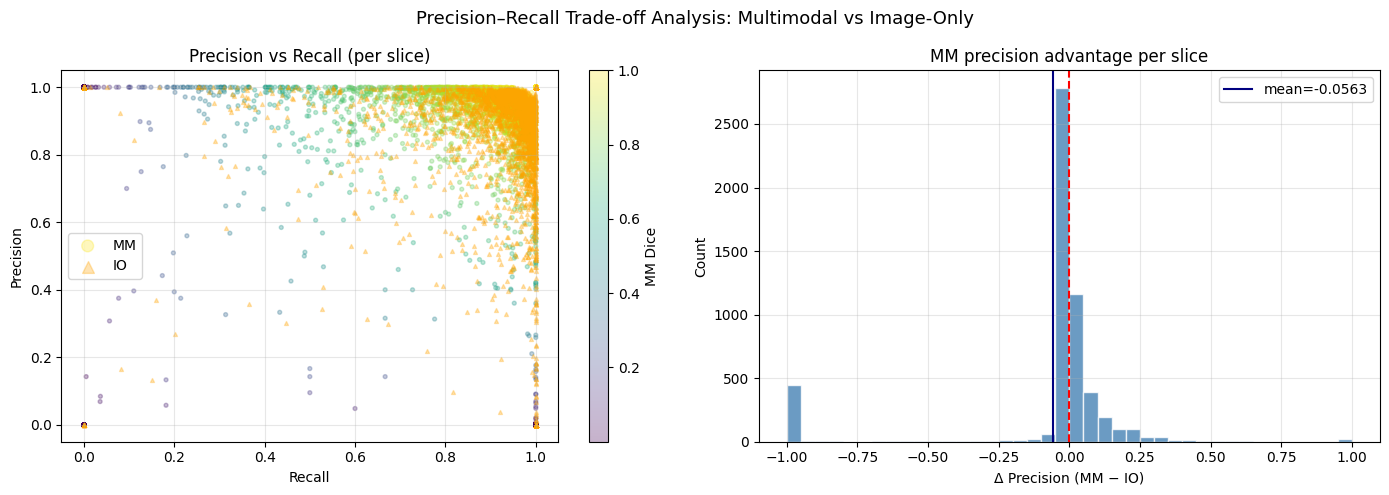

Saved: outputs/figures/fig_precision_recall_tradeoff.png


In [11]:
# ── Precision–Recall Trade-off Analysis ──────────────────────────────────────
# Self-contained: loads from outputs/results_table.csv
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(OUT_DIR / "results_table.csv")
prec_mm = df["precision_mm"].values; prec_io = df["precision_io"].values
rec_mm  = df["recall_mm"].values;    rec_io  = df["recall_io"].values
dice_mm = df["dice_mm"].values

# ── Statistics ────────────────────────────────────────────────────────────────
mm_wins_prec = (prec_mm > prec_io).mean() * 100
io_wins_rec  = (rec_io  > rec_mm ).mean() * 100
delta_prec   = (prec_mm - prec_io).mean()
delta_rec    = (rec_io  - rec_mm ).mean()

print(f"Slices where MM precision > IO precision: {mm_wins_prec:.1f}%")
print(f"Slices where IO recall > MM recall: {io_wins_rec:.1f}%")
print(f"Mean precision advantage (MM - IO): {delta_prec:+.4f}")
print(f"Mean recall advantage (IO - MM): {delta_rec:+.4f}")

# ── Figure ────────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: scatter (recall vs precision), coloured by Dice
sc = ax1.scatter(rec_mm, prec_mm, c=dice_mm, cmap="viridis", alpha=0.3, s=8, label="MM")
ax1.scatter(rec_io, prec_io, c="orange", alpha=0.3, s=8, marker="^", label="IO")
fig.colorbar(sc, ax=ax1, label="MM Dice")
ax1.set_xlabel("Recall"); ax1.set_ylabel("Precision")
ax1.set_title("Precision vs Recall (per slice)")
ax1.legend(markerscale=3); ax1.grid(True, alpha=0.3)

# Right: histogram of (precision_MM - precision_IO)
delta = prec_mm - prec_io
ax2.hist(delta, bins=40, color="steelblue", edgecolor="white", alpha=0.8)
ax2.axvline(0, color="red", linewidth=1.5, linestyle="--")
ax2.axvline(delta.mean(), color="navy", linewidth=1.5, linestyle="-", label=f"mean={delta.mean():+.4f}")
ax2.set_xlabel("\u0394 Precision (MM \u2212 IO)"); ax2.set_ylabel("Count")
ax2.set_title("MM precision advantage per slice")
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle("Precision\u2013Recall Trade-off Analysis: Multimodal vs Image-Only", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR/"fig_precision_recall_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: outputs/figures/fig_precision_recall_tradeoff.png")


## Cell — Tumor-slice vs All-slice Metrics
**Improvement 5 — Tumor-Containing Slices Metrics**

Loads `results_table.csv` and computes mean metrics separately for all slices and for tumor-containing slices (where `has_tumor == 1`). Provides a clearer picture of model performance on clinically relevant slices.

## Cell 21 — Output Inventory Check

Scans `outputs/` and `checkpoints/` and prints a checklist of every expected deliverable file with its size on disk.

A `[OK]` means the file exists and was generated successfully.
A `[MISS]` means the corresponding cell has not been run yet or saved to a different path.

Use this cell before submission to confirm all required files are present:
- `best_model.pth` and `best_model_image_only.pth` (trained checkpoints)
- `training_log.csv` and `training_log_image_only.csv` (epoch logs)
- `results_table.csv` (per-slice evaluation metrics)
- All figure PNGs in `outputs/figures/`

In [22]:
import os; from pathlib import Path
ON_KAGGLE = os.path.exists("/kaggle/input")
OUT_DIR   = Path("/kaggle/working/outputs")     if ON_KAGGLE else Path(".").resolve()/"outputs"
CKPT_DIR  = Path("/kaggle/working/checkpoints") if ON_KAGGLE else Path(".").resolve()/"checkpoints"
FIG_DIR   = OUT_DIR/"figures"
print("="*50, "\nOUTPUT INVENTORY\n"+"="*50)
for sec, files in [
    ("Checkpoints",[CKPT_DIR/"best_model.pth", CKPT_DIR/"best_model_image_only.pth"]),
    ("Logs",       [OUT_DIR/"clip_text_embeddings.pt", OUT_DIR/"training_log.csv",
                    OUT_DIR/"training_log_image_only.csv", OUT_DIR/"results_table.csv"]),
    ("Figures",    list(FIG_DIR.glob("*.png")) if FIG_DIR.exists() else [])]:
    print(f"\n{sec}:")
    for p in files:
        ok=Path(p).exists()
        print(f"  [{'OK' if ok else 'MISS'}] {Path(p).name}{(' ('+str(round(Path(p).stat().st_size/1e6,1))+' MB)') if ok else ''}")


OUTPUT INVENTORY

Checkpoints:
  [OK] best_model.pth (105.5 MB)
  [OK] best_model_image_only.pth (105.5 MB)

Logs:
  [OK] clip_text_embeddings.pt (0.8 MB)
  [OK] training_log.csv (0.0 MB)
  [OK] training_log_image_only.csv (0.0 MB)
  [OK] results_table.csv (0.6 MB)

Figures:
  [OK] fig4_segmentation_grid.png (0.8 MB)
  [OK] fig_dice_distribution.png (0.0 MB)
  [OK] fig2_iou_vs_epoch.png (0.0 MB)
  [OK] fig_ablation.png (0.0 MB)
  [OK] fig_training_curves.png (0.2 MB)
  [OK] fig_segmentation_grid.png (0.6 MB)
  [OK] fig3_loss_vs_epoch_image_only.png (0.0 MB)
  [OK] fig1_dice_vs_epoch.png (0.0 MB)
  [OK] fig1_dice_vs_epoch_image_only.png (0.0 MB)
  [OK] fig3_loss_vs_epoch.png (0.0 MB)
  [OK] fig5_attention_maps.png (0.7 MB)
  [OK] fig2_iou_vs_epoch_image_only.png (0.0 MB)
  [OK] fig_failure_cases.png (0.9 MB)
